In [2]:
import os
import warnings
import tqdm
import pandas as pd
import numpy as np

warnings.filterwarnings("ignore")
warnings.simplefilter(action="ignore", category=pd.errors.PerformanceWarning)

In [3]:
%load_ext autoreload
%autoreload 2

In [4]:
datafolder = "../data"
spadl_h5 = os.path.join(datafolder, "women-statsbomb3.h5")

In [5]:
games = pd.read_hdf(spadl_h5, "games")
print("nb of games:", len(games))

nb of games: 126


## Compute features

In [6]:
# ── Pitch / event constants
# StatsBomb coordinate system: possession team always attacks toward x = 120
ATT_THIRD_X = 80.0          # boundary of the attacking third

TOUCH_TYPES = {
    "Pass", "Carry", "Shot", "Dribble", "Ball Recovery",
    "Clearance", "Interception", "Miscontrol", "Dispossessed",
    "Block",
}
DEFENSIVE_TYPES = {
    "Pressure", "Duel", "Block", "Interception", "Clearance", "Ball Recovery",
}
EXCLUDE_TYPES = {
    "Starting XI", "Half Start", "Half End", "Tactical Shift",
    "Substitution", "Bad Behaviour", "Referee Ball-Drop",
}

# ── Helper functions ───────────────

def parse_sub(extra, event_type):
    """Return the event-specific sub-dict from the extra field."""
    key = {"Pass": "pass", "Carry": "carry", "Shot": "shot"}.get(event_type, "")
    return extra.get(key, {}) if isinstance(extra, dict) and key else {}


def compute_ball_distances(att_events):
    """Return (D_t, D_f, D_x): possession-team ball travel distances.

    - D_t : total Euclidean travel (passes use pass.length; carries use
            hypot(Δx, Δy)). Used for distance_per_second / distance_per_touch.
    - D_f : forward longitudinal travel = Σ max(Δx, 0).
    - D_x : total longitudinal travel  = Σ |Δx|.
    D_f / D_x is a dimensionally consistent forward-progression rate.

    Vectorised: pulls columns as numpy arrays once and uses list
    comprehensions over the object-typed `extra` / `location` fields
    instead of DataFrame.iterrows.
    """
    if len(att_events) == 0:
        return 0.0, 0.0, 0.0

    types  = att_events["type_name"].to_numpy()
    locs   = att_events["location"].to_numpy(dtype=object)
    extras = att_events["extra"].to_numpy(dtype=object)

    is_pass  = types == "Pass"
    is_carry = types == "Carry"

    def _end(ex, key):
        if not isinstance(ex, dict):
            return None
        sub = ex.get(key)
        return sub.get("end_location") if isinstance(sub, dict) else None

    def _pass_len(ex):
        if not isinstance(ex, dict):
            return 0.0
        sub = ex.get("pass")
        return (sub.get("length", 0.0) or 0.0) if isinstance(sub, dict) else 0.0

    def _dx(ex, loc, key):
        end = _end(ex, key)
        if isinstance(end, list) and isinstance(loc, list):
            return end[0] - loc[0]
        return 0.0

    def _dy(ex, loc, key):
        end = _end(ex, key)
        if isinstance(end, list) and isinstance(loc, list):
            return end[1] - loc[1]
        return 0.0

    p_len = np.array([_pass_len(e) for e in extras[is_pass]], dtype=float)
    p_dx  = np.array([_dx(e, l, "pass")  for e, l in zip(extras[is_pass],  locs[is_pass])],  dtype=float)

    c_dx  = np.array([_dx(e, l, "carry") for e, l in zip(extras[is_carry], locs[is_carry])], dtype=float)
    c_dy  = np.array([_dy(e, l, "carry") for e, l in zip(extras[is_carry], locs[is_carry])], dtype=float)
    c_len = np.hypot(c_dx, c_dy)

    D_t = float(p_len.sum() + c_len.sum())
    all_dx = np.concatenate([p_dx, c_dx]) if (p_dx.size or c_dx.size) else np.array([0.0])
    D_f = float(np.maximum(all_dx, 0.0).sum())
    D_x = float(np.abs(all_dx).sum())
    return D_t, D_f, D_x


def parse_freeze_frame(ff):
    """Split a 360 freeze frame into outfield player-location lists.

    Returns:
        att_field : possession-team outfield players (no GK)
        def_field : defending-team outfield players  (no GK)
    Goalkeepers are excluded from both groups so that team centroids and
    compactness metrics reflect the active shape rather than being anchored
    by the keeper sitting deep in their own box.
    """
    att_field, def_field = [], []
    if not isinstance(ff, list):
        return att_field, def_field
    for p in ff:
        loc = p.get("location")
        if not (isinstance(loc, list) and len(loc) >= 2):
            continue
        if p.get("keeper", False):
            continue
        xy = loc[:2]
        if p.get("teammate", False):
            att_field.append(xy)
        else:
            def_field.append(xy)
    return att_field, def_field


def _cv(values):
    """Coefficient of variation (std / mean); NaN if fewer than 2 values."""
    if len(values) < 2:
        return np.nan
    a  = np.asarray(values, dtype=float)
    mu = a.mean()
    return float(a.std() / mu) if mu != 0 else np.nan


def _spread_rate(vals, times):
    """Mean |Δ(length/width) / Δt| — first-order rate of shape-ratio change.

    Renamed from `_spread_accel`: the quantity is a rate (first time
    derivative), not an acceleration (second derivative).
    """
    if len(vals) < 2:
        return np.nan
    sv = np.asarray(vals,  dtype=float)
    st = np.asarray(times, dtype=float)
    dt = np.diff(st)
    ok = dt > 0
    rate = np.abs(np.diff(sv)[ok] / dt[ok])
    rate = rate[rate < 10.0]
    return float(np.mean(rate)) if len(rate) > 0 else np.nan


def _inter_pass_interval(grp, team_id):
    """
    PoP(ai) = Tai - Tai-1
    Tai: 当前球员传球时间（球离脚）
    Tai-1: 上一个队友传球时间（球离脚）
    """
    grp = grp.reset_index(drop=True)
    pop_deltas = []
    
    passes_idx = [
        i for i, (t, tid) in enumerate(zip(grp["type_name"], grp["team_id"]))
        if t == "Pass" and tid == team_id
    ]
    for i in passes_idx:
        cur = grp.iloc[i]
        prev = grp.iloc[:i]
        if len(prev) == 0:
            continue
        team_passes = prev[
            (prev["type_name"] == "Pass")
            & (prev["team_id"] == cur["team_id"])
            & (prev["player_id"] != cur["player_id"])
        ]
        own_intercepts = prev[
            (prev["type_name"] == "Interception")
            & (prev["player_id"] == cur["player_id"])
        ]
        combined = pd.concat([team_passes, own_intercepts]).sort_index()
        if len(combined) == 0:
            continue
            
        if "time_s" in cur:
            delta = cur["time_s"] - combined.iloc[-1]["time_s"]
        else:
            delta = (cur["timestamp"] - combined.iloc[-1]["timestamp"]).total_seconds()

        if 0 <= delta <= 30:
            pop_deltas.append(delta)

    return float(np.mean(pop_deltas)) if pop_deltas else np.nan

def _distance_per_second(grp, team_id):
    SHEN_EXCLUDE = {
        "Starting XI", "Half Start", "Pressure", "Miscontrol",
        "Tactical Shift", "Half End", "Player Off", "Substitution",
        "Foul Won", "Dribbled Past", "Shield", "Bad Behaviour",
    }
    sh = grp[~grp["type_name"].isin(SHEN_EXCLUDE)].copy()
    sh["x"] = sh["location"].apply(lambda loc: loc[0] if isinstance(loc, list) else np.nan)
    sh["y"] = sh["location"].apply(lambda loc: loc[1] if isinstance(loc, list) else np.nan)
    sh = sh.dropna(subset=["x", "y"]).reset_index(drop=True)
    opp = sh["team_id"] != team_id
    sh.loc[opp, "x"] = 120 - sh.loc[opp, "x"]
    sh.loc[opp, "y"] =  80 - sh.loc[opp, "y"]
    if len(sh) >= 3:
        coords = sh[["x", "y"]].to_numpy()
        dist = float(np.linalg.norm(np.diff(coords, axis=0), axis=1).sum())
        dur_sec = (
            (sh["minute"].iloc[-1] + sh["second"].iloc[-1] / 60)
            - (sh["minute"].iloc[0]  + sh["second"].iloc[0]  / 60)
        ) * 60
        return dist / dur_sec if dur_sec > 0 else np.nan
    return np.nan

In [7]:
def compute_pace_metrics(events):
    """Compute possession-level game pace metrics from raw StatsBomb events.

    Appendix metrics
    ────────────────
    Activity Intensity
      passes_per_minute          : 60 · N_passes_all / T_p
                                   N_passes_all = every "Pass" event in the
                                   possession window (no actor-team filter,
                                   matching baseline_passes_per_min's broad
                                   numerator). Denominator T_p stays the
                                   absolute wall-clock span (≥ 2 s).
      distance_per_second        : Shen 2022-style — Σd(consecutive events)
                                   / t_span over events outside SHEN_EXCLUDE,
                                   with defender-frame coordinate flip
                                   (`_distance_per_second`).
      distance_per_touch         : D_t / T_touches  (possession-team Euclidean)
      time_to_pass               : Bransen & Davis 2025 — possession-mean of
                                   per-pass Δt = T_ai − T_(a,i−1) restricted
                                   to passes by the possession team
                                   (`_inter_pass_interval`).

    Directional Intent
      attacking_transition_time  : t_{final-third} – t_{start}  (only if possession started outside att third)
      time_to_shot               : t_{shot} – t_{start}  (capped at 90 s)
      team_centroid_speed        : dC/dt  (from 360 freeze frames, outfield only, dt > 100 ms)
      forward_progression_rate   : D_f / D_x   (forward / total longitudinal travel)
      attack_rearline_variability: CV of deepest outfield attacker x-position over time
      team_spread_rate           : |d/dt(length/width)| (from 360)
      inter_team_longitudinal_dist : mean(x_def) – mean(x_att) across 360 frames

    Constraint
      pressing_frequency         : N_defensive / T_p
      spatial_compression_x      : mean SD of attacker x-positions (from 360)
      spatial_compression_y      : mean SD of attacker y-positions (from 360)
      defensive_line_variability : CV of last outfield defender x-position over time
      pass_completion_rate       : N_successful / N_passes

    Parameters
    ----------
    events : pd.DataFrame
        Raw StatsBomb events for a single game (from HDF5 events/game_{id}).

    Returns
    -------
    pd.DataFrame  – one row per (possession, possession_team_id)
    """
    events = events[~events["type_name"].isin(EXCLUDE_TYPES)].copy()
    events["time_s"] = events["timestamp"].dt.total_seconds()

    rows = []

    for (poss_id, poss_team_id), grp in events.groupby(
        ["possession", "possession_team_id"], sort=False
    ):
        grp  = grp.sort_values("index")
        att  = grp[grp["team_id"] == poss_team_id]   # possession team
        defe = grp[grp["team_id"] != poss_team_id]   # defending team
        if len(att) == 0:
            continue

        # ── Period boundary guard ───
        # `timestamp` resets at each period, so a possession that spans a
        # period split would produce a nonsense T_p. Drop such cases.
        if grp["period_id"].nunique() > 1:
            continue

        # ── Duration ─────────────────
        # Use grp (both teams' events) as the time window so that t_start and
        # T_p share the same baseline — avoids mixing "possession-team first
        # action" with "any event during possession".
        t_start = grp["time_s"].min()
        t_end   = grp["time_s"].max()
        T_p     = t_end - t_start

        if T_p < 3.0:
            continue

        # ── Ball distances ───────
        D_t, D_f, D_x = compute_ball_distances(att)

        # ── Passes ────────────────
        # Two pass views:
        #   passes_poss : actor == possession_team — used for pass_completion_rate
        #   N_passes    : every "Pass" event in the possession (no actor filter)
        #                 — used for passes_per_minute, harmonised with the broad
        #                 baseline_passes_per_min numerator.
        passes_poss = att[att["type_name"] == "Pass"]
        N_passes    = int((grp["type_name"] == "Pass").sum())
        # A pass is failed when the pass sub-dict contains an "outcome" key
        n_success = sum(
            1 for ex in passes_poss["extra"]
            if not (isinstance(ex, dict) and "outcome" in ex.get("pass", {}))
        )

        # ── Touches ───────────
        T_touches = att["type_name"].isin(TOUCH_TYPES).sum()

        # ── Shot timing ────────
        shots  = att[att["type_name"] == "Shot"]
        t_shot = shots["time_s"].min() if len(shots) > 0 else np.nan

        # ── Entry into attacking third (x > 80) ────────────────
        # Only meaningful if the possession did not already start in the
        # attacking third (turnovers, deep restarts, etc.).
        first_loc = att["location"].iloc[0] if len(att) > 0 else None
        started_outside_att3 = (
            isinstance(first_loc, list) and len(first_loc) > 0 and first_loc[0] <= ATT_THIRD_X
        )
        if started_outside_att3:
            in_att3 = att[att["location"].apply(
                lambda loc: isinstance(loc, list) and loc[0] > ATT_THIRD_X
            )]
            t_att3 = in_att3["time_s"].min() if len(in_att3) > 0 else np.nan
        else:
            t_att3 = np.nan

        # ── 360-frame-derived metrics (vectorised over the att rows) ───
        att_360 = att[att["freeze_frame_360"].notna()]
        ff_list = att_360["freeze_frame_360"].to_numpy(dtype=object)
        tt_list = att_360["time_s"].to_numpy(dtype=float)

        centroids, c_times      = [], []
        att_last_x, def_last_x  = [], []
        spread_vals, sp_times   = [], []
        sp_x_list,  sp_y_list   = [], []
        inter_dist_list         = []

        for ff, t in zip(ff_list, tt_list):
            att_field, def_field = parse_freeze_frame(ff)

            # Outfield attackers
            if len(att_field) >= 2:
                arr = np.asarray(att_field, dtype=float)
                xs  = arr[:, 0]
                ys  = arr[:, 1]
                # Team centroid uses outfield only — keeper excluded to avoid
                # anchoring the centroid in the own box.
                centroids.append(arr.mean(axis=0))
                c_times.append(t)
                att_last_x.append(float(xs.min()))            # deepest attacker
                sp_x_list.append(float(xs.std()))             # longitudinal dispersion
                sp_y_list.append(float(ys.std()))             # lateral dispersion
                length = float(xs.max() - xs.min())
                width  = float(ys.max() - ys.min())
                if width > 0:
                    spread_vals.append(length / width)
                    sp_times.append(t)

                # Inter-team longitudinal distance (requires both sides visible)
                if len(def_field) >= 2:
                    def_arr = np.asarray(def_field, dtype=float)
                    inter_dist_list.append(float(def_arr[:, 0].mean() - xs.mean()))

            # Outfield defenders
            if len(def_field) >= 2:
                # max-x defender = last man / offside line (closest to defending goal)
                def_last_x.append(float(max(p[0] for p in def_field)))

        # Team centroid speed: filter dt > 100 ms to avoid numerical blow-up
        if len(centroids) >= 2:
            c  = np.asarray(centroids, dtype=float)
            ct = np.asarray(c_times,   dtype=float)
            dt = np.diff(ct)
            d  = np.linalg.norm(np.diff(c, axis=0), axis=1)
            ok = dt > 0.1                              # ≥ 100 ms between frames
            speeds = d[ok] / dt[ok]
            speeds = speeds[speeds < 12.0]
            team_centroid_speed = float(np.mean(speeds)) if len(speeds) > 0 else np.nan
        else:
            team_centroid_speed = np.nan

        N_d = defe["type_name"].isin(DEFENSIVE_TYPES).sum()

        rows.append({
            "game_id":              grp["game_id"].iloc[0],
            "possession":           poss_id,
            "possession_team_id":   poss_team_id,
            "possession_team_name": grp["possession_team_name"].iloc[0],
            "period_id":            grp["period_id"].iloc[0],
            "T_p":                  T_p,
            "N_passes":             N_passes,
            # ── Activity Intensity
            "passes_per_minute":    60.0 * N_passes / T_p if T_p > 0 else np.nan,
            "distance_per_second":  _distance_per_second(grp, poss_team_id),
            "distance_per_touch":   D_t / T_touches if T_touches > 0 else np.nan,
            "time_to_pass":  _inter_pass_interval(grp, poss_team_id),
            # ── Directional Intent
            "attacking_transition_time": (t_att3 - t_start) if (not np.isnan(t_att3) and (t_att3 - t_start) <= 90.0) else np.nan,
            "time_to_shot":              (t_shot - t_start) if (not np.isnan(t_shot) and (t_shot - t_start) <= 90.0) else np.nan,
            "team_centroid_speed":       team_centroid_speed,
            "forward_progression_rate":  D_f / D_x if D_x > 0 else np.nan,
            "attack_rearline_variability": _cv(att_last_x),
            "team_spread_rate":          _spread_rate(spread_vals, sp_times),
            "inter_team_longitudinal_dist": float(np.mean(inter_dist_list)) if inter_dist_list else np.nan,
            # ── Constraint
            "pressing_frequency":    N_d / T_p if T_p > 0 else np.nan,
            "spatial_compression_x": float(np.mean(sp_x_list)) if sp_x_list else np.nan,
            "spatial_compression_y": float(np.mean(sp_y_list)) if sp_y_list else np.nan,
            "defensive_line_variability": _cv(def_last_x),
            "pass_completion_rate":  n_success / len(passes_poss) if len(passes_poss) > 0 else np.nan,
        })

    return pd.DataFrame(rows)

## Baseline tempo metrics (prior work)

Four possession-level metrics from the literature, replicated verbatim from `1-mload-and-convert-statsbomb-data.ipynb` so we can benchmark our latent factor against them under the same mixed-model design.

In [8]:
def compute_baseline_metrics(events):
    """Compute four published tempo baselines at possession level.

    Baselines
    ──────────
      baseline_passes_per_min              : Stein et al. (2018) — 60 · N_passes / T_p
                                             T_p = wall-clock span of EXCLUDE_TYPES-filtered
                                             events (same source as passes_per_minute);
                                             drops possessions with T_p < 2 s.
      baseline_time_to_pass                : Bransen & Davis (2025) — mean Δt per pass across
                                             the possession. Δt = Tai − Tai−1 where Tai−1 is
                                             the most recent teammate pass or own interception.
                                             Filter: 0 ≤ Δt ≤ 30 s.
      baseline_meters_per_touch_per_second : Hamilton (2013) — Σd / (k · t_span).
                                             Touches = {Pass, Carry, Clearance, Dribble,
                                             Shot, Goal Keeper, Interception}; for Pass/Shot/
                                             Carry d uses event end_location.
      baseline_meters_per_second           : Shen (2022) — Σd / t_span over consecutive events
                                             after an exclusion list.

    t_span in Hamilton/Shen is wall-clock minute+second span (1 s granularity),
    matching the prior definitions literally. Away-team coordinate flipping
    from notebook 1 is dropped because all four metrics are direction-
    invariant (they use Euclidean distance or no coordinates at all).

    Parameters
    ----------
    events : pd.DataFrame
        Raw StatsBomb events for a single game.

    Returns
    -------
    pd.DataFrame  – one row per (possession, possession_team_id) with the
                    four baseline columns (NaN where not computable).
    """
    HAM_TOUCHES   = {"Pass", "Carry", "Clearance", "Dribble", "Shot",
                     "Goal Keeper", "Interception"}
    SHEN_EXCLUDE  = {
        "Starting XI", "Half Start", "Pressure", "Miscontrol",
        "Tactical Shift", "Half End", "Player Off", "Substitution",
        "Foul Won", "Dribbled Past", "Shield", "Bad Behaviour",
    }

    ev = events[~events["type_name"].isin(EXCLUDE_TYPES)].copy()
    if not pd.api.types.is_timedelta64_dtype(ev["timestamp"]):
        ev["timestamp"] = pd.to_timedelta(ev["timestamp"])
    ev["_ts"] = ev["timestamp"].dt.total_seconds()

    rows = []
    for (poss_id, team_id), grp in ev.groupby(
        ["possession", "possession_team_id"], sort=False
    ):
        grp = grp.sort_values("index").reset_index(drop=True)

        # ── 1. Stein 2018: passes_per_min ( EXCLUDE_TYPES-filtered) ─
        T_p = grp["_ts"].max() - grp["_ts"].min()
        if T_p >= 3.0:
            n_pass = int((grp["type_name"] == "Pass").sum())
            bppm = 60.0 * n_pass / T_p
        else:
            bppm = np.nan

        # ── 2. Bransen & Davis: time_to_pass (possession-mean of PoP) ───
        pop_deltas = []
        passes_idx = [
            i for i, (t, tid) in enumerate(zip(grp["type_name"], grp["team_id"]))
            if t == "Pass" and tid == team_id
        ]
        for i in passes_idx:
            cur = grp.iloc[i]
            prev = grp.iloc[:i]
            if len(prev) == 0:
                continue
            team_passes = prev[
                (prev["type_name"] == "Pass")
                & (prev["team_id"] == cur["team_id"])
                & (prev["player_id"] != cur["player_id"])
            ]
            own_intercepts = prev[
                (prev["type_name"] == "Interception")
                & (prev["player_id"] == cur["player_id"])
            ]
            combined = pd.concat([team_passes, own_intercepts]).sort_index()
            if len(combined) == 0:
                continue
            delta = cur["_ts"] - combined.iloc[-1]["_ts"]
            if 0 <= delta <= 30:
                pop_deltas.append(delta)
        btt = float(np.mean(pop_deltas)) if pop_deltas else np.nan

        # ── 3. Hamilton 2013: meters_per_touch_per_second ─────────
        h = grp[grp["type_name"].isin(HAM_TOUCHES)].copy()
        h["x"] = h["location"].apply(lambda loc: loc[0] if isinstance(loc, list) else np.nan)
        h["y"] = h["location"].apply(lambda loc: loc[1] if isinstance(loc, list) else np.nan)
        h = h.dropna(subset=["x", "y"]).reset_index(drop=True)
        opp_h = (h["team_id"] != team_id).to_numpy()
        h["x_u"] = np.where(opp_h, 120 - h["x"], h["x"])
        h["y_u"] = np.where(opp_h,  80 - h["y"], h["y"])
        if len(h) >= 2:
            t_span = (h["minute"].iloc[-1] * 60 + h["second"].iloc[-1]) - \
                     (h["minute"].iloc[0]  * 60 + h["second"].iloc[0])
            if t_span > 0:
                total_d = 0.0
                for j in range(len(h)):
                    et = h["type_name"].iloc[j]
                    if et in ("Pass", "Shot", "Carry"):
                        sub = parse_sub(h["extra"].iloc[j], et)
                        end = sub.get("end_location")
                        if isinstance(end, list) and len(end) >= 2:
                            dx = end[0] - h["x"].iloc[j]
                            dy = end[1] - h["y"].iloc[j]
                            total_d += float(np.hypot(dx, dy))
                    elif j < len(h) - 1:
                        dx = h["x_u"].iloc[j + 1] - h["x_u"].iloc[j]
                        dy = h["y_u"].iloc[j + 1] - h["y_u"].iloc[j]
                        total_d += float(np.hypot(dx, dy))
                bmtps = total_d / (len(h) * t_span)
            else:
                bmtps = np.nan
        else:
            bmtps = np.nan

        # ── 4. Shen 2022: meters_per_second ───────────────
        sh = grp[~grp["type_name"].isin(SHEN_EXCLUDE)].copy()
        sh["x"] = sh["location"].apply(lambda loc: loc[0] if isinstance(loc, list) else np.nan)
        sh["y"] = sh["location"].apply(lambda loc: loc[1] if isinstance(loc, list) else np.nan)
        sh = sh.dropna(subset=["x", "y"]).reset_index(drop=True)
        opp = sh["team_id"] != team_id
        sh.loc[opp, "x"] = 120 - sh.loc[opp, "x"]
        sh.loc[opp, "y"] =  80 - sh.loc[opp, "y"]
        if len(sh) >= 3:
            coords = sh[["x", "y"]].to_numpy()
            dist = float(np.linalg.norm(np.diff(coords, axis=0), axis=1).sum())
            dur_sec = (
                (sh["minute"].iloc[-1] + sh["second"].iloc[-1] / 60)
                - (sh["minute"].iloc[0]  + sh["second"].iloc[0]  / 60)
            ) * 60
            bmps = dist / dur_sec if dur_sec > 0 else np.nan
        else:
            bmps = np.nan

        rows.append({
            "game_id":            grp["game_id"].iloc[0],
            "possession":         poss_id,
            "possession_team_id": team_id,
            "baseline_passes_per_min":              bppm,
            "baseline_time_to_pass":                btt,
            "baseline_meters_per_touch_per_second": bmtps,
            "baseline_meters_per_second":           bmps,
        })
    return pd.DataFrame(rows)

In [9]:
all_features = []

for gid in tqdm.tqdm(games["game_id"].tolist(), desc="Computing pace metrics"):
    try:
        events = pd.read_hdf(spadl_h5, f"events/game_{gid}")
        latent   = compute_pace_metrics(events)
        baseline = compute_baseline_metrics(events)
        # Merge latent indicators + 4  baselines 
        merged   = latent.merge(
            baseline, on=["game_id", "possession", "possession_team_id"], how="left"
        )
        all_features.append(merged)
    except Exception as e:
        print(f"  Warning: game {gid} skipped – {e}")

features_df = pd.concat(all_features, ignore_index=True)

print(f"Total possessions                    : {len(features_df):,}")
print(f"  with shots                         : {features_df['time_to_shot'].notna().sum():,}")
print(f"  with 360 centroid data             : {features_df['team_centroid_speed'].notna().sum():,}")
print(f"  with inter-team longitudinal dist  : {features_df['inter_team_longitudinal_dist'].notna().sum():,}")
print(f"  with baseline_passes_per_min       : {features_df['baseline_passes_per_min'].notna().sum():,}")
print(f"  with baseline_time_to_pass         : {features_df['baseline_time_to_pass'].notna().sum():,}")
print(f"  with baseline_meters/touch/s       : {features_df['baseline_meters_per_touch_per_second'].notna().sum():,}")
print(f"  with baseline_meters/s             : {features_df['baseline_meters_per_second'].notna().sum():,}")
features_df.head()

Computing pace metrics: 100%|██████████| 126/126 [02:47<00:00,  1.33s/it]

Total possessions                    : 19,999
  with shots                         : 2,668
  with 360 centroid data             : 18,384
  with inter-team longitudinal dist  : 19,699
  with baseline_passes_per_min       : 19,999
  with baseline_time_to_pass         : 17,288
  with baseline_meters/touch/s       : 19,466
  with baseline_meters/s             : 19,647


,game_id,possession,possession_team_id,possession_team_name,period_id,T_p,N_passes,passes_per_minute,distance_per_second,distance_per_touch,...,inter_team_longitudinal_dist,pressing_frequency,spatial_compression_x,spatial_compression_y,defensive_line_variability,pass_completion_rate,baseline_passes_per_min,baseline_time_to_pass,baseline_meters_per_touch_per_second,baseline_meters_per_second
0,4020846,2,865,England Women's,1,12.583,4,19.073353,11.688127,16.656917,...,5.493969,0.317889,10.958952,12.085384,0.067040,1.000000,19.073353,2.871333,1.943307,11.688127
1,4020846,4,865,England Women's,1,22.175,8,21.645998,10.273562,14.028921,...,2.926609,0.135287,9.416492,13.386014,0.240813,0.875000,21.645998,2.498143,0.637678,10.273562
2,4020846,5,865,England Women's,1,11.770,4,20.390824,10.519902,25.364538,...,4.562138,0.169924,8.113141,17.345381,0.082317,0.750000,20.390824,3.923333,2.305867,10.519902
3,4020846,6,863,Spain Women's,1,45.444,11,14.523369,6.340962,13.066870,...,6.003368,0.022005,8.509817,15.546132,0.195632,0.818182,14.523369,3.449700,0.325931,6.340962
4,4020846,7,865,England Women's,1,55.106,13,14.154539,7.340337,12.581295,...,2.617099,0.127028,7.425474,15.020523,0.308447,0.923077,14.154539,4.005250,0.252666,7.340337


In [10]:
features_df.to_hdf(spadl_h5, key="pace_features", mode="a", complevel=5)
print(f"Saved pace_features → {spadl_h5}  ({len(features_df):,} rows)\n")

metric_groups = {
    "Activity Intensity": [
        "passes_per_minute", "distance_per_second",
        "distance_per_touch", "time_to_pass",
    ],
    "Directional Intent": [
        "attacking_transition_time", "time_to_shot",
        "team_centroid_speed", "forward_progression_rate",
        "attack_rearline_variability", "team_spread_rate",
        "inter_team_longitudinal_dist",
    ],
    "Constraint": [
        "pressing_frequency",
        "spatial_compression_x", "spatial_compression_y",
        "defensive_line_variability", "pass_completion_rate",
    ],
    "Baseline (prior work)": [
        "baseline_passes_per_min",
        "baseline_time_to_pass",
        "baseline_meters_per_touch_per_second",
        "baseline_meters_per_second",
    ],
}

for group, cols in metric_groups.items():
    print(f"=== {group} ===")
    print(features_df[cols].describe().round(4).to_string())
    print()

Saved pace_features → ../data/women-statsbomb3.h5  (19,999 rows)

=== Activity Intensity ===
       passes_per_minute  distance_per_second  distance_per_touch  time_to_pass
count         19999.0000           19647.0000          19972.0000    17288.0000
mean             19.1605               8.6850             14.2823        3.6084
std               8.7061               3.0875              9.4448        1.7062
min               0.0000               0.0663              0.0000        0.2970
25%              14.0906               7.0116              9.2572        2.6076
50%              18.0802               8.2402             12.1755        3.3488
75%              22.8484               9.7968             15.9613        4.2270
max              79.6020              67.4433            100.5038       27.4030

=== Directional Intent ===
       attacking_transition_time  time_to_shot  team_centroid_speed  forward_progression_rate  attack_rearline_variability  team_spread_rate  inter_team_longit

## Men's tournaments — load / compute pace features

In [11]:
men_h5 = os.path.join(datafolder, "men-statsbomb.h5")
men_games = pd.read_hdf(men_h5, "games")
print(f"Men games: {len(men_games)}")

men_features_list = []
for gid in tqdm.tqdm(men_games["game_id"].tolist(), desc="Men pace metrics"):
    try:
        ev = pd.read_hdf(men_h5, f"events/game_{gid}")
        latent   = compute_pace_metrics(ev)
        baseline = compute_baseline_metrics(ev)
        men_features_list.append(
            latent.merge(baseline, on=["game_id", "possession", "possession_team_id"], how="left")
        )
    except Exception as e:
        print(f"  Warning: game {gid} skipped – {e}")

men_features_df = pd.concat(men_features_list, ignore_index=True)
men_features_df.to_hdf(men_h5, key="pace_features", mode="a", complevel=5)
print(f"Saved → {men_h5}  ({len(men_features_df):,} possessions)")
men_features_df.describe().round(3)

Men games: 166


Men pace metrics: 100%|██████████| 166/166 [04:06<00:00,  1.48s/it]


Saved → ../data/men-statsbomb.h5  (23,774 possessions)


,game_id,possession,possession_team_id,period_id,T_p,N_passes,passes_per_minute,distance_per_second,distance_per_touch,time_to_pass,...,inter_team_longitudinal_dist,pressing_frequency,spatial_compression_x,spatial_compression_y,defensive_line_variability,pass_completion_rate,baseline_passes_per_min,baseline_time_to_pass,baseline_meters_per_touch_per_second,baseline_meters_per_second
count,23774.000,23774.000,23774.000,23774.000,23774.000,23774.000,23774.000,23257.000,23753.000,21158.000,...,23471.000,23774.000,23483.000,23483.000,22887.000,23510.000,23774.000,21158.000,22979.000,23257.000
mean,3860482.243,88.325,988.207,1.581,29.237,7.279,19.479,9.223,15.733,3.410,...,3.914,0.150,8.922,14.889,0.201,0.774,19.479,3.410,1.801,9.223
std,56357.074,53.053,616.454,0.617,115.710,6.932,8.017,3.171,11.648,1.466,...,2.410,0.146,2.011,3.322,0.134,0.266,8.017,1.466,2.851,3.171
min,3788741.000,2.000,768.000,1.000,3.000,0.000,0.000,0.182,0.000,0.230,...,-13.379,0.000,0.067,2.660,0.000,0.000,0.000,0.230,0.046,0.182
25%,3794690.000,44.000,776.000,1.000,8.340,3.000,15.067,7.444,10.291,2.604,...,2.493,0.051,7.656,12.600,0.106,0.667,15.067,2.604,0.428,7.444
50%,3857285.000,86.000,787.000,2.000,16.801,5.000,18.605,8.640,12.836,3.214,...,3.918,0.112,8.853,15.169,0.184,0.857,18.605,3.214,0.871,8.640
75%,3930165.000,129.000,912.000,2.000,32.537,10.000,22.785,10.303,16.729,3.916,...,5.338,0.209,10.139,17.309,0.272,1.000,22.785,3.916,1.888,10.303
max,3943043.000,274.000,4885.000,4.000,3215.592,76.000,78.611,61.716,108.060,27.553,...,21.755,1.431,22.649,25.973,1.154,1.000,78.611,27.553,59.783,61.716


## Combined dataset — men + women

In [12]:
# ── load & tag 
women_f = pd.read_hdf(spadl_h5, "pace_features")
women_g = pd.read_hdf(spadl_h5, "games")[["game_id","competition_id","season_id"]]
men_f   = pd.read_hdf(men_h5,   "pace_features")
men_g   = pd.read_hdf(men_h5,   "games")[["game_id","competition_id","season_id"]]

SEASON_LABEL = {
    (53,106):"WEURO2022",(53,315):"WEURO2025",(72,107):"WWC2023",
    (43,106):"WC2022",  (55, 43):"EURO2020",  (55,282):"EURO2024",
}

def tag(feats, games_meta):
    df = feats.merge(games_meta, on="game_id", how="left")
    df["tournament"] = df.apply(
        lambda r: SEASON_LABEL.get((r.competition_id, r.season_id), "Unknown"), axis=1)
    df["gender"] = df["competition_id"].apply(
        lambda c: "Women" if c in (53,72) else "Men")
    return df

combined = pd.concat([
    tag(women_f, women_g),
    tag(men_f,   men_g),
], ignore_index=True)

print(f"Combined possessions: {len(combined):,}")
print(combined.groupby(["gender","tournament"]).size().to_string())

Combined possessions: 43,773
gender  tournament
Men     EURO2020       7439
        EURO2024       6953
        WC2022         9382
Women   WEURO2022      4764
        WEURO2025      4838
        WWC2023       10397


## Long-format table for mixed linear models

Emit one row per `(possession × metric)` with gender / tournament / season covariates + game_id and possession_team_id as random-effect keys.

In [13]:
## Long-format export for mixed linear models
METRIC_COLS = [
    # latent indicators (anchor + primary candidates)
    "passes_per_minute",
    "distance_per_second",
    "time_to_pass",
    # four baselines
    "baseline_passes_per_min",
    "baseline_time_to_pass",
    "baseline_meters_per_touch_per_second",
    "baseline_meters_per_second",
]
ID_COLS = ["game_id", "possession", "possession_team_id", "period_id",
           "gender", "tournament", "season_id", "competition_id"]

long_df = combined[ID_COLS + METRIC_COLS].melt(
    id_vars=ID_COLS, value_vars=METRIC_COLS,
    var_name="metric", value_name="value",
).dropna(subset=["value"]).reset_index(drop=True)

# ── Winsorise at [P1, P99] within each metric before z-scoring ───────────────
# Extreme outliers (z > 15–20) in distance_per_second, baseline_meters_per_touch_
# per_second, inter_pass_interval etc. would otherwise dominate the z-scale.
# P99 z-scores are all ≈ 3.4–4.3 SD, so clipping at P1/P99 only removes the
# extreme tail without distorting the bulk of the distribution.
def _winsorise(s):
    lo, hi = s.quantile(0.01), s.quantile(0.99)
    return s.clip(lo, hi)

long_df["value"] = long_df.groupby("metric")["value"].transform(_winsorise)

# z-scored values (within metric, on winsorised values)
long_df["value_z"] = (
    long_df.groupby("metric")["value"].transform(lambda s: (s - s.mean()) / s.std(ddof=0))
)

print(f"Long-format rows: {len(long_df):,}")
print(long_df.groupby("metric")["value"].agg(["count", "mean", "std"]).round(3).to_string())
print()
print("Post-winsorise z(max) per metric:")
print(long_df.groupby("metric")["value_z"].agg(["min","max"]).round(2).to_string())

# Persist both wide (combined) and long tables — stored on the women h5 by
# convention since it already holds the tournament master list.
combined.to_hdf(spadl_h5, key="combined_features",      mode="a", complevel=5)
long_df .to_hdf(spadl_h5, key="combined_features_long", mode="a", complevel=5)
print(f"\nSaved combined_features / combined_features_long → {spadl_h5}")


Long-format rows: 292,691
                                      count    mean    std
metric                                                    
baseline_meters_per_second            42904   8.947  2.920
baseline_meters_per_touch_per_second  42445   1.782  2.402
baseline_passes_per_min               43773  19.265  8.051
baseline_time_to_pass                 38446   3.475  1.429
distance_per_second                   42904   8.947  2.920
passes_per_minute                     43773  19.265  8.051
time_to_pass                          38446   3.475  1.429

Post-winsorise z(max) per metric:
                                       min   max
metric                                          
baseline_meters_per_second           -1.97  3.92
baseline_meters_per_touch_per_second -0.69  5.05
baseline_passes_per_min              -2.39  3.53
baseline_time_to_pass                -1.74  4.05
distance_per_second                  -1.97  3.92
passes_per_minute                    -2.39  3.53
time_to_pass    

## EFA Pipeline — Composite Tempo Index

### Step 1 — Preprocessing

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from factor_analyzer import FactorAnalyzer
from factor_analyzer.factor_analyzer import calculate_kmo, calculate_bartlett_sphericity

# ── Feature pool (exclude time_to_shot: 86% NaN) 
ALL_FEATURES = [
    "passes_per_minute", "distance_per_second", "distance_per_touch",
    "time_to_pass",                           # invert
    "attacking_transition_time",                     # invert
    "team_centroid_speed", "forward_progression_rate",
    "attack_rearline_variability", "team_spread_rate",
    "inter_team_longitudinal_dist",
    "pressing_frequency",
    "spatial_compression_x", "spatial_compression_y",
    "defensive_line_variability", "pass_completion_rate",
]
INVERT = {"time_to_pass", "attacking_transition_time"}

efa_raw = combined[ALL_FEATURES].copy()

# Structural NaN → 95th-pct of observed (slowest plausible value before inversion)
for col in ["attacking_transition_time", "time_to_pass"]:
    efa_raw[col] = efa_raw[col].fillna(efa_raw[col].quantile(0.95))

efa_raw = efa_raw.dropna()
print(f"Rows after dropping NaN: {len(efa_raw):,} / {len(combined):,}")

# Sign inversion (higher value = higher tempo)
for col in INVERT:
    efa_raw[col] = -efa_raw[col]

# Winsorise at [P1, P99]
for col in ALL_FEATURES:
    lo, hi = efa_raw[col].quantile(0.01), efa_raw[col].quantile(0.99)
    efa_raw[col] = efa_raw[col].clip(lo, hi)

# Z-score standardise
scaler = StandardScaler()
X = pd.DataFrame(scaler.fit_transform(efa_raw), columns=ALL_FEATURES)
print(f"Feature matrix: {X.shape[0]:,} × {X.shape[1]}")
print(X.describe().round(3))

# ── Residualise X against gender + tournament (remove group mean shifts) ──────
# EFA will see only within-group covariance; scoring will use globally
# standardised X so between-group differences are preserved in TI_efa.
_meta    = combined.loc[efa_raw.index, ["gender", "tournament"]]
_dummies = pd.get_dummies(_meta, columns=["gender", "tournament"],
                          drop_first=True).astype(float)
X_resid  = X.copy()
for _col in ALL_FEATURES:
    _lr = LinearRegression(fit_intercept=True).fit(_dummies, X[_col])
    X_resid[_col] = X[_col] - _lr.predict(_dummies)

print(f"\nResidualised X: {X_resid.shape}  (gender + tournament shifts removed)")
print(X_resid.describe().round(3))

Rows after dropping NaN: 39,995 / 43,773
Feature matrix: 39,995 × 15
       passes_per_minute  distance_per_second  distance_per_touch  \
count          39995.000            39995.000           39995.000   
mean              -0.000               -0.000              -0.000   
std                1.000                1.000               1.000   
min               -2.078               -2.056              -1.595   
25%               -0.608               -0.603              -0.598   
50%               -0.134               -0.145              -0.182   
75%                0.435                0.439               0.344   
max                3.670                3.789               4.317   

       time_to_pass  attacking_transition_time  team_centroid_speed  \
count     39995.000                  39995.000            39995.000   
mean         -0.000                     -0.000                0.000   
std           1.000                      1.000                1.000   
min          -3.511      

### Step 2 — Variable screening (correlation filter)

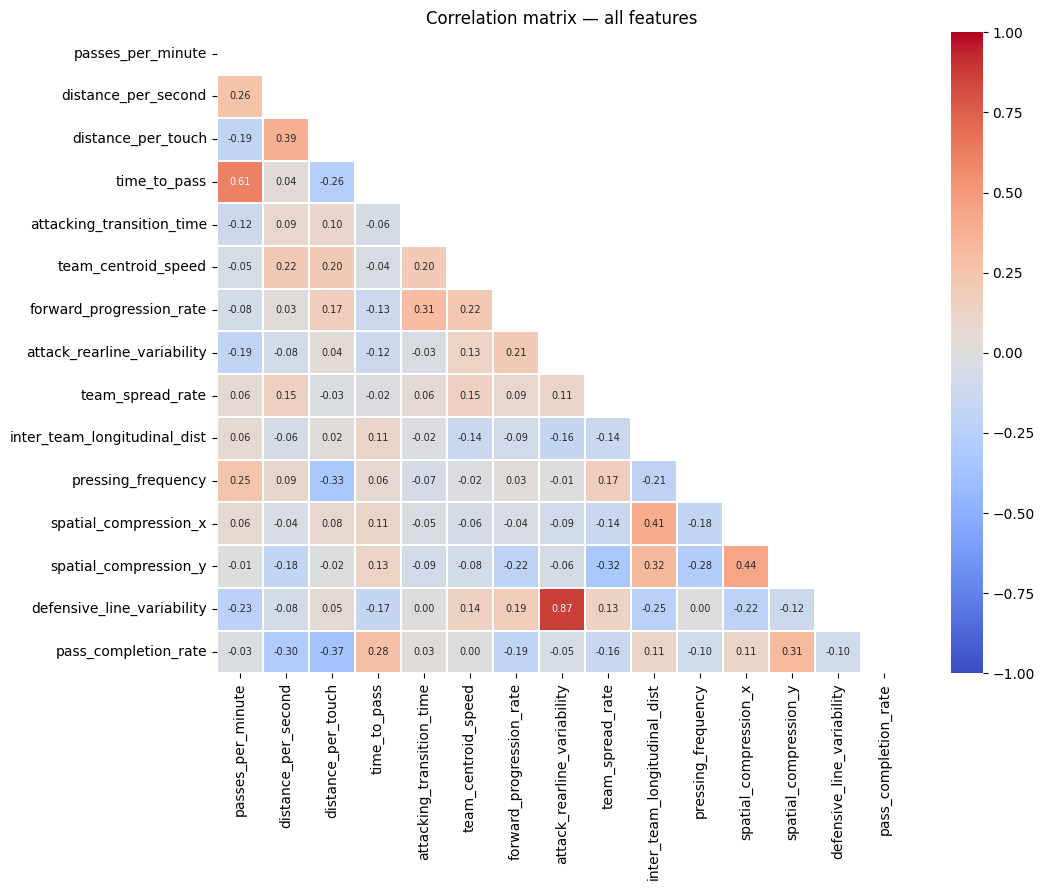

Low-correlation variables (max|r|<0.20): []
  Redundant: |r(attack_rearline_variability,defensive_line_variability)|=0.874 → drop defensive_line_variability

Retained after screening: 14 features
['passes_per_minute', 'distance_per_second', 'distance_per_touch', 'time_to_pass', 'attacking_transition_time', 'team_centroid_speed', 'forward_progression_rate', 'attack_rearline_variability', 'team_spread_rate', 'inter_team_longitudinal_dist', 'pressing_frequency', 'spatial_compression_x', 'spatial_compression_y', 'pass_completion_rate']


In [15]:
corr = X_resid.corr()  # screen on residualised correlations

# ── Plot full correlation matrix 
fig, ax = plt.subplots(figsize=(11, 9))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, vmin=-1, vmax=1, ax=ax,
            annot_kws={"size": 7}, linewidths=0.3)
ax.set_title("Correlation matrix — all features", fontsize=12)
plt.tight_layout(); plt.show()

# ── Low correlation: max|r| with any other variable < 0.2 
max_corr = corr.abs().apply(lambda col: col[col.index != col.name].max())
low_corr_vars = max_corr[max_corr < 0.20].index.tolist()
print(f"Low-correlation variables (max|r|<0.20): {low_corr_vars}")

# ── Redundant: |r| > 0.85 → keep variable with higher mean |r| 
removed_redundant = set()
for i, v1 in enumerate(ALL_FEATURES):
    for v2 in ALL_FEATURES[i+1:]:
        if v1 in removed_redundant or v2 in removed_redundant:
            continue
        if abs(corr.loc[v1, v2]) > 0.8:
            keep = v1 if max_corr[v1] >= max_corr[v2] else v2
            drop = v2 if keep == v1 else v1
            removed_redundant.add(drop)
            print(f"  Redundant: |r({v1},{v2})|={abs(corr.loc[v1,v2]):.3f} → drop {drop}")

drop_vars = set(low_corr_vars) | removed_redundant
FEATURES_S2 = [f for f in ALL_FEATURES if f not in drop_vars]
X_s2       = X[FEATURES_S2].copy()        # global z-score → used for scoring
X_s2_resid = X_resid[FEATURES_S2].copy()  # residualised   → used for EFA fit
print(f"\nRetained after screening: {len(FEATURES_S2)} features")
print(FEATURES_S2)

### Step 3 — Factorability checks (KMO & Bartlett)

In [16]:
kmo_all, kmo_model = calculate_kmo(X_s2_resid)
chi2_val, p_val    = calculate_bartlett_sphericity(X_s2_resid)

print("=== KMO per variable ===")
for feat, k in sorted(zip(FEATURES_S2, kmo_all), key=lambda x: x[1]):
    flag = " ← low (<0.60)" if k < 0.60 else ""
    print(f"  {feat:<35s}  KMO = {k:.4f}{flag}")

print(f"\nOverall KMO = {kmo_model:.4f}  ", end="")
if   kmo_model >= 0.90: print("(marvellous)")
elif kmo_model >= 0.80: print("(meritorious)")
elif kmo_model >= 0.70: print("(middling)")
elif kmo_model >= 0.60: print("(mediocre)")
else:                   print("(unacceptable — EFA not recommended)")

print(f"\nBartlett's test  χ²={chi2_val:.2f}  p={p_val:.2e}")
print("Sphericity rejected → factor structure present." if p_val < 0.05
      else "Sphericity NOT rejected → EFA may not be appropriate.")

=== KMO per variable ===
  passes_per_minute                    KMO = 0.5169 ← low (<0.60)
  attacking_transition_time            KMO = 0.5461 ← low (<0.60)
  distance_per_touch                   KMO = 0.5629 ← low (<0.60)
  distance_per_second                  KMO = 0.5683 ← low (<0.60)
  time_to_pass                         KMO = 0.5698 ← low (<0.60)
  attack_rearline_variability          KMO = 0.5935 ← low (<0.60)
  forward_progression_rate             KMO = 0.5956 ← low (<0.60)
  pass_completion_rate                 KMO = 0.6148
  pressing_frequency                   KMO = 0.6263
  team_centroid_speed                  KMO = 0.6560
  spatial_compression_x                KMO = 0.6832
  spatial_compression_y                KMO = 0.7154
  team_spread_rate                     KMO = 0.7264
  inter_team_longitudinal_dist         KMO = 0.7466

Overall KMO = 0.6132  (mediocre)

Bartlett's test  χ²=111411.93  p=0.00e+00
Sphericity rejected → factor structure present.


### Step 4 — Exploratory Factor Analysis

Factors with eigenvalue > 1 (Kaiser): 5
  Factor 1: λ = 2.5776
  Factor 2: λ = 2.0243
  Factor 3: λ = 1.6550
  Factor 4: λ = 1.3193
  Factor 5: λ = 1.0205
  Factor 6: λ = 0.9829
  Factor 7: λ = 0.8715
  Factor 8: λ = 0.7617
Factors retained by parallel analysis (95th pct): 5


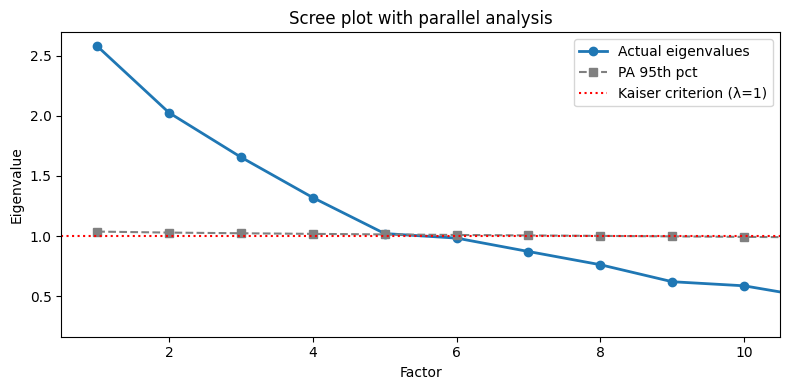


Fitting EFA with 5 factors (promax oblique rotation)...

=== Pattern matrix (promax) ===
                                 F1     F2     F3     F4     F5     h2
passes_per_minute             0.977 -0.024  0.114  0.127 -0.029  0.984
distance_per_second           0.262 -0.141  0.522 -0.117  0.260  0.442
distance_per_touch           -0.236  0.262  0.702 -0.045  0.253  0.683
time_to_pass                  0.684  0.083 -0.224  0.008  0.145  0.545
attacking_transition_time    -0.000  0.017 -0.022  0.181  0.329  0.142
team_centroid_speed           0.045 -0.117  0.040  0.018  0.517  0.285
forward_progression_rate      0.112  0.188  0.060  1.007  0.242  1.125
attack_rearline_variability  -0.171 -0.105 -0.055  0.120  0.076  0.064
team_spread_rate              0.069 -0.347  0.071  0.018  0.089  0.139
inter_team_longitudinal_dist  0.120  0.569  0.052  0.100 -0.106  0.362
pressing_frequency            0.229 -0.447 -0.077  0.070 -0.171  0.293
spatial_compression_x         0.141  0.644  0.069  0.139 -

In [17]:
# ── Eigenvalues 
fa_eigen = FactorAnalyzer(n_factors=len(FEATURES_S2), rotation=None)
fa_eigen.fit(X_s2_resid)
ev, _ = fa_eigen.get_eigenvalues()

n_factors_kaiser = int((ev > 1).sum())
print(f"Factors with eigenvalue > 1 (Kaiser): {n_factors_kaiser}")
for i, e in enumerate(ev[:8], 1):
    print(f"  Factor {i}: λ = {e:.4f}")

# ── Parallel analysis (500 permutations, 95th pct) 
np.random.seed(42)
N_PA, N_VARS, N_PERM = len(X_s2_resid), len(FEATURES_S2), 500
pa_eigs = np.zeros((N_PERM, N_VARS))
for p in range(N_PERM):
    rand_data = np.random.normal(size=(N_PA, N_VARS))
    rand_corr = np.corrcoef(rand_data.T)
    pa_eigs[p] = np.linalg.eigvalsh(rand_corr)[::-1]

pa_95 = np.percentile(pa_eigs, 95, axis=0)
n_factors_pa = int((ev[:N_VARS] > pa_95).sum())
print(f"Factors retained by parallel analysis (95th pct): {n_factors_pa}")

# ── Scree plot ────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 4))
xs = np.arange(1, N_VARS + 1)
ax.plot(xs, ev[:N_VARS], "o-", label="Actual eigenvalues", lw=2)
ax.plot(xs[:N_VARS], pa_95, "s--", color="gray", label="PA 95th pct", lw=1.5)
ax.axhline(1, color="red", ls=":", label="Kaiser criterion (λ=1)")
ax.set(xlabel="Factor", ylabel="Eigenvalue", title="Scree plot with parallel analysis")
ax.legend(); ax.set_xlim(0.5, min(N_VARS, 10) + 0.5)
plt.tight_layout(); plt.show()

# ── Fit EFA with promax (oblique) ─────────────────────────────────────────────
# Oblique rotation replaces varimax: (a) the sub-dimensions of match tempo
# (passing rate, running density, spatial compression, …) are not theoretically
# independent in football, and (b) the downstream Horst composite (Step 8) is
# built from the |inter-item correlation matrix|, which is statistically
# coherent only when factors are permitted to correlate.
N_FACTORS = max(n_factors_pa, 2)   # at least 2 factors
print(f"\nFitting EFA with {N_FACTORS} factors (promax oblique rotation)...")
fa = FactorAnalyzer(n_factors=N_FACTORS, rotation="promax")
fa.fit(X_s2_resid)  # pure tactical weights (group shifts removed)

loadings   = pd.DataFrame(fa.loadings_,   index=FEATURES_S2,
                           columns=[f"F{i+1}" for i in range(N_FACTORS)])
communal   = pd.Series(fa.get_communalities(), index=FEATURES_S2, name="h2")
var_exp    = fa.get_factor_variance()

print("\n=== Pattern matrix (promax) ===")
disp = loadings.copy()
disp["h2"] = communal
print(disp.round(3).to_string())

print("\n=== Factor inter-correlation matrix Φ (promax, oblique) ===")
phi = pd.DataFrame(fa.phi_,
                   index=[f"F{i+1}" for i in range(N_FACTORS)],
                   columns=[f"F{i+1}" for i in range(N_FACTORS)])
print(phi.round(3).to_string())
_off = fa.phi_[np.triu_indices_from(fa.phi_, k=1)]
print(f"|Φ off-diagonal|: mean={np.mean(np.abs(_off)):.3f}  max={np.max(np.abs(_off)):.3f}")

print("\n=== Variance explained ===")
for i, (ss, prop, cum) in enumerate(zip(*var_exp), 1):
    print(f"  F{i}: SS={ss:.3f}  Var%={prop*100:.1f}%  Cum%={cum*100:.1f}%")

### Step 5 — Factor interpretation

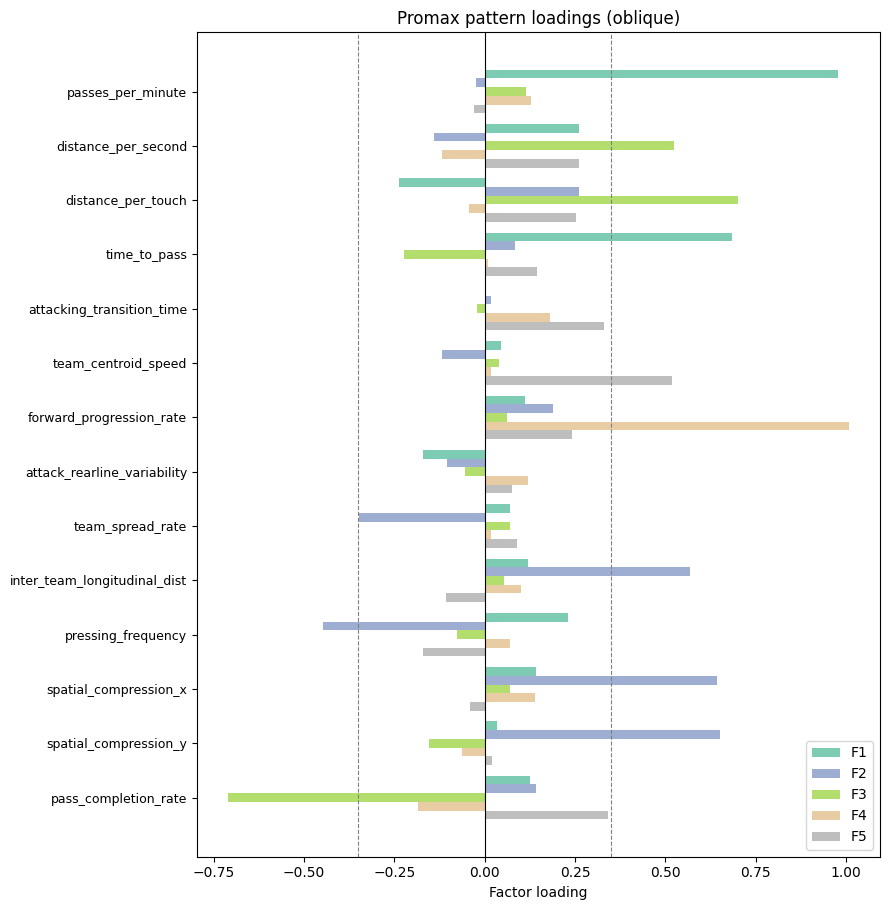

Tempo factor (highest loading on 'passes_per_minute'): F1

  F1  ← TEMPO   top loadings: [('passes_per_minute', 0.98), ('time_to_pass', 0.68), ('distance_per_second', 0.26), ('distance_per_touch', 0.24), ('pressing_frequency', 0.23)]
  F2            top loadings: [('spatial_compression_y', 0.65), ('spatial_compression_x', 0.64), ('inter_team_longitudinal_dist', 0.57), ('pressing_frequency', 0.45), ('team_spread_rate', 0.35)]
  F3            top loadings: [('pass_completion_rate', 0.71), ('distance_per_touch', 0.7), ('distance_per_second', 0.52), ('time_to_pass', 0.22), ('spatial_compression_y', 0.15)]
  F4            top loadings: [('forward_progression_rate', 1.01), ('pass_completion_rate', 0.19), ('attacking_transition_time', 0.18), ('spatial_compression_x', 0.14), ('passes_per_minute', 0.13)]
  F5            top loadings: [('team_centroid_speed', 0.52), ('pass_completion_rate', 0.34), ('attacking_transition_time', 0.33), ('distance_per_second', 0.26), ('distance_per_touch', 0.25)]


In [18]:
LOAD_THRESH = 0.35   

fig, ax = plt.subplots(figsize=(9, 0.55 * len(FEATURES_S2) + 1.5))
colors_f = plt.cm.Set2(np.linspace(0, 1, N_FACTORS))
x_pos    = np.arange(len(FEATURES_S2))

bar_w = 0.8 / N_FACTORS
for fi in range(N_FACTORS):
    vals = loadings[f"F{fi+1}"].values
    offsets = (fi - (N_FACTORS - 1) / 2) * bar_w
    ax.barh(x_pos + offsets, vals, bar_w,
            color=colors_f[fi], alpha=0.85, label=f"F{fi+1}")

ax.axvline(0,           color="black", lw=0.8)
ax.axvline( LOAD_THRESH, color="gray", lw=0.8, ls="--")
ax.axvline(-LOAD_THRESH, color="gray", lw=0.8, ls="--")
ax.set_yticks(x_pos)
ax.set_yticklabels(FEATURES_S2, fontsize=9)
ax.set(xlabel="Factor loading", title="Promax pattern loadings (oblique)")
ax.legend(loc="lower right"); ax.invert_yaxis()
plt.tight_layout(); plt.show()

# ── Identify tempo factor = highest loading on passes_per_minute 
ANCHOR = "passes_per_minute"
tempo_factor_idx = loadings.loc[ANCHOR].abs().idxmax()
print(f"Tempo factor (highest loading on '{ANCHOR}'): {tempo_factor_idx}")
print()
for fi in range(N_FACTORS):
    col = f"F{fi+1}"
    top = loadings[col].abs().nlargest(5)
    sign = "+" if loadings.loc[ANCHOR, col] > 0 else "−"
    print(f"  {col}  {'← TEMPO' if col==tempo_factor_idx else '':8s}"
          f"  top loadings: {list(zip(top.index, top.round(2)))}")

### Step 6 — Factor refinement

In [19]:
LOW_H2     = 0.30
LOW_LOAD   = 0.40
CROSS_DIFF = 0.15   # flag if top-2 loadings differ by less than this

def _pa_n_factors(data, n_perm=200, seed=42):
    """Parallel analysis: number of factors whose eigenvalue exceeds the
    95-th-percentile of random-data eigenvalues."""
    n, p = data.shape
    obs_ev = np.linalg.eigvalsh(np.corrcoef(data.values, rowvar=False))[::-1]
    rng = np.random.default_rng(seed)
    rand_ev = np.empty((n_perm, p))
    for i in range(n_perm):
        rand_ev[i] = np.linalg.eigvalsh(
            np.corrcoef(rng.standard_normal((n, p)).T))[::-1]
    return int((obs_ev > np.percentile(rand_ev, 95, axis=0)).sum())

def _flag_vars(L, h2, low_h2=LOW_H2, low_load=LOW_LOAD, cross_diff=CROSS_DIFF):
    issues = {}
    for v in L.index:
        row = L.loc[v].abs().sort_values(ascending=False)
        probs = []
        if h2[v] < low_h2:
            probs.append(f"h²={h2[v]:.3f} < {low_h2}")
        if row.iloc[0] < low_load:
            probs.append(f"max|load|={row.iloc[0]:.3f} < {low_load}")
        if len(row) > 1 and (row.iloc[0] - row.iloc[1]) < cross_diff:
            probs.append(f"Δ(top1,top2)={row.iloc[0]-row.iloc[1]:.3f} < {cross_diff}")
        if probs:
            issues[v] = probs
    return issues

# ── Iterative refinement: re-evaluate N_FACTORS via PA after every removal ───
features = list(FEATURES_S2)
print("Iterative refinement (Promax oblique, PA re-evaluated per round)")
for it in range(1, 21):
    n_fac = max(_pa_n_factors(X_resid[features]), 2)
    fa_it = FactorAnalyzer(n_factors=n_fac, rotation="promax").fit(X_resid[features])
    L_it  = pd.DataFrame(fa_it.loadings_, index=features,
                         columns=[f"F{i+1}" for i in range(n_fac)])
    h2_it = pd.Series(fa_it.get_communalities(), index=features)
    bad   = _flag_vars(L_it, h2_it)
    print(f"  iter {it:2d}: k={len(features):2d}, PA→N={n_fac}, drop={list(bad) or '—'}")
    if not bad:
        break
    if len(features) - len(bad) < n_fac + 2:
        print(f"  ⚠ stopping: removing {list(bad)} would leave k<N+2")
        break
    features = [f for f in features if f not in bad]

# ── Finalise 
FEATURES_FINAL = features
N_FACTORS_FINAL = n_fac
X_final        = X[FEATURES_FINAL].copy()        # global z-score (for scoring)
X_final_resid  = X_resid[FEATURES_FINAL].copy()  # residualised   (for EFA fit)

fa_final   = fa_it
loadings_f = L_it
communal_f = h2_it.rename("h2")
var_exp_f  = fa_final.get_factor_variance()

print(f"\nFinal feature set ({len(FEATURES_FINAL)} vars × {N_FACTORS_FINAL} factors)")
print(FEATURES_FINAL)

print("\n=== Final pattern matrix (promax) ===")
disp = loadings_f.copy(); disp["h2"] = communal_f
print(disp.round(3).to_string())

print("\n=== Final factor inter-correlation matrix Φ ===")
phi_f = pd.DataFrame(fa_final.phi_,
                     index=[f"F{i+1}" for i in range(N_FACTORS_FINAL)],
                     columns=[f"F{i+1}" for i in range(N_FACTORS_FINAL)])
print(phi_f.round(3).to_string())
_off = fa_final.phi_[np.triu_indices_from(fa_final.phi_, k=1)]
print(f"|Φ off-diagonal|: mean={np.mean(np.abs(_off)):.3f}  "
      f"max={np.max(np.abs(_off)):.3f}")

# Health checks
heywood = (loadings_f.abs() > 1.0).any().any()
single_var_factors = [f"F{i+1}" for i in range(N_FACTORS_FINAL)
                      if int((loadings_f.iloc[:, i].abs() > 0.40).sum()) < 2]
print(f"\nHealth: Heywood (|λ|>1)? {heywood}   "
      f"Single-variable factors: {single_var_factors or 'none'}")

print("\n=== Final Variance Explained (Promax) ===")
var_metrics = ["SS Loadings", "Proportion Var", "Cumulative Var"]
df_var = pd.DataFrame(var_exp_f, index=var_metrics, 
                      columns=[f"F{i+1}" for i in range(N_FACTORS_FINAL)])

df_var_pct = df_var.copy()
df_var_pct.loc["Proportion Var"] *= 100
df_var_pct.loc["Cumulative Var"] *= 100

print(df_var_pct.round(3).to_string())

Iterative refinement (Promax oblique, PA re-evaluated per round)
  iter  1: k=14, PA→N=5, drop=['attacking_transition_time', 'team_centroid_speed', 'attack_rearline_variability', 'team_spread_rate', 'pressing_frequency']
  iter  2: k= 9, PA→N=3, drop=['forward_progression_rate', 'inter_team_longitudinal_dist']
  iter  3: k= 7, PA→N=3, drop=—

Final feature set (7 vars × 3 factors)
['passes_per_minute', 'distance_per_second', 'distance_per_touch', 'time_to_pass', 'spatial_compression_x', 'spatial_compression_y', 'pass_completion_rate']

=== Final pattern matrix (promax) ===
                          F1     F2     F3     h2
passes_per_minute      0.958  0.171 -0.031  0.948
distance_per_second    0.246  0.608 -0.023  0.431
distance_per_touch    -0.229  0.758  0.261  0.695
time_to_pass           0.663 -0.142  0.092  0.469
spatial_compression_x  0.051  0.080  0.544  0.305
spatial_compression_y -0.023 -0.097  0.813  0.670
pass_completion_rate   0.066 -0.520  0.191  0.311

=== Final factor in

### Step 7 — Tempo index construction (EFA factor scores)

In [20]:
# Identify tempo factor (highest loading on passes_per_minute)
tempo_col = loadings_f.loc["passes_per_minute"].abs().idxmax()
tempo_fi  = int(tempo_col[1:]) - 1          # robust for F1..F99

# ── Score: regression weights from residualised EFA → applied to global X ────
# W_score = R_resid^{-1} @ L  (regression method, same formula as fa.transform)
# Using X_final_resid's correlation matrix so weights reflect within-group
# covariance only; multiplied by X_final (global z-score) to preserve
# between-group mean differences in TI_efa.
L       = fa_final.loadings_                              # (n_feat, n_factors)
R_resid = np.corrcoef(X_final_resid.values, rowvar=False) # residualised corr
W_score = np.linalg.lstsq(R_resid, L, rcond=None)[0]      # (n_feat, n_factors)

scores = X_final.values @ W_score  # (N, n_factors)
TI_efa = pd.Series(scores[:, tempo_fi], name="TI_efa")

# Re-attach metadata (rows aligned with efa_raw index)
meta_idx = efa_raw.index
tempo_df = combined.loc[meta_idx, ["game_id", "possession", "possession_team_id",
                                   "tournament", "gender"]].copy()
tempo_df["TI_efa"] = TI_efa.values

# Store all factor scores (global scoring) for downstream clustering
for _fi in range(scores.shape[1]):
    tempo_df[f"F{_fi+1}"] = scores[:, _fi]

print("TI_efa statistics:")
print(tempo_df["TI_efa"].describe().round(4))
print("\nMean TI_efa by tournament:")
print(tempo_df.groupby(["gender", "tournament"])["TI_efa"].mean().round(4).to_string())
print(f"\nFactor score columns saved: {[f'F{i+1}' for i in range(scores.shape[1])]}")

TI_efa statistics:
count    39995.0000
mean        -0.0000
std          0.9667
min         -2.5178
25%         -0.5913
50%         -0.1075
75%          0.4458
max          3.6846
Name: TI_efa, dtype: float64

Mean TI_efa by tournament:
gender  tournament
Men     EURO2020      0.0380
        EURO2024      0.0035
        WC2022        0.0391
Women   WEURO2022     0.0076
        WEURO2025     0.0142
        WWC2023      -0.0755

Factor score columns saved: ['F1', 'F2', 'F3']


### Step 8 — Horst method comparison

In [21]:
# ── Horst composite tempo index (column-sum weights) ──────────────────────────
# Robustness check vs the EFA factor-score index (TI_efa). The Horst composite
# weights each retained item by the normalised column-sum of the |residualised
# inter-item correlation| matrix, then applies those weights to the globally
# standardised features (X_final) so between-group means are preserved. The raw
# composite is finally z-standardised to give TI_horst.
_w_horst = X_final_resid[FEATURES_FINAL].corr().abs().sum(axis=0)
_w_horst = _w_horst / _w_horst.sum()
_horst_raw = X_final[FEATURES_FINAL].values @ _w_horst.values
TI_horst = pd.Series((_horst_raw - _horst_raw.mean()) / _horst_raw.std(ddof=0),
                     index=TI_efa.index, name="TI_horst")          # z-standardised
r_compare = float(np.corrcoef(TI_efa, TI_horst)[0, 1])

print("Horst column-sum weights:")
print(_w_horst.round(3).to_string())
print(f"\nTI_horst: mean={TI_horst.mean():.3f}  sd={TI_horst.std():.3f}")
print(f"Convergent validity  r(TI_efa, TI_horst) = {r_compare:.4f}")

Horst column-sum weights:
passes_per_minute        0.140
distance_per_second      0.143
distance_per_touch       0.150
time_to_pass             0.157
spatial_compression_x    0.119
spatial_compression_y    0.135
pass_completion_rate     0.156

TI_horst: mean=-0.000  sd=1.000
Convergent validity  r(TI_efa, TI_horst) = 0.5809


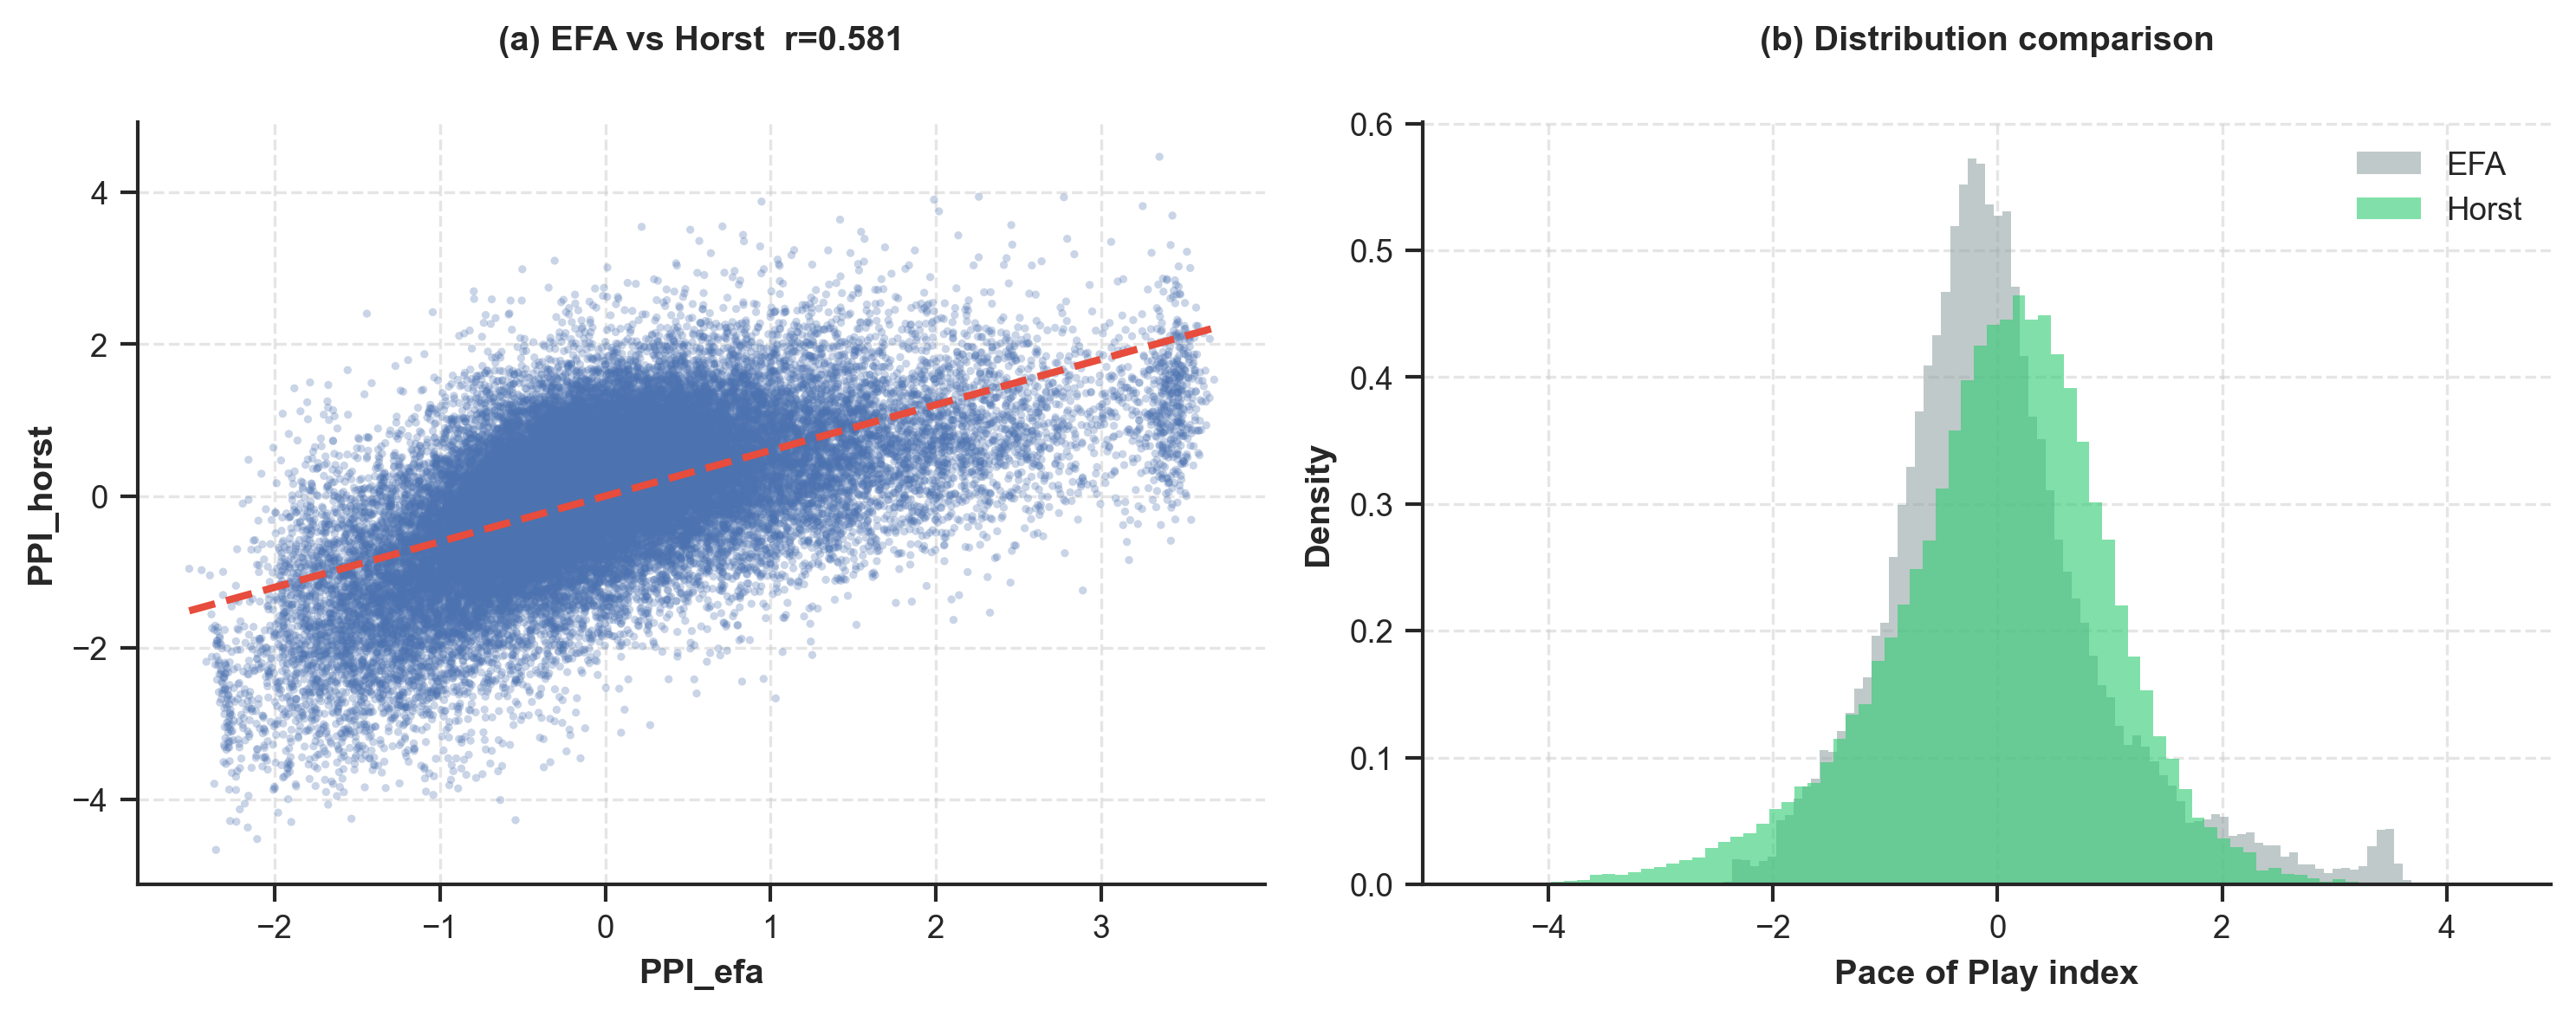

In [22]:
# ── Comparison plot 
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman']
sns.set_theme(style="ticks", context="paper")

fig, axes = plt.subplots(1, 2, figsize=(10, 4), dpi=300)
m, b = np.polyfit(TI_efa, TI_horst, 1)
x_vals = np.array([TI_efa.min(), TI_efa.max()])
axes[0].plot(x_vals, m*x_vals + b, color="#e74c3c", lw=2, ls="--")
axes[0].scatter(TI_efa, TI_horst, alpha=0.3, s=5, edgecolor="none")
axes[0].set_xlabel("PPI_efa", fontweight="bold")
axes[0].set_ylabel("PPI_horst", fontweight="bold")
axes[0].set_title(f"(a) EFA vs Horst  r={r_compare:.3f}", pad=20, fontweight="bold")

for method_name, ti_vals in [("EFA", TI_efa), ("Horst", TI_horst)]:
    tempo_df[f"TI_{method_name.lower()}"] = ti_vals.values

for ti_vals, label, color in [(TI_efa,"EFA","#95a5a6"),(TI_horst,"Horst","#2ecc71")]:
    axes[1].hist(ti_vals, bins=80, alpha=0.6, density=True, label=label, color=color, edgecolor="none")
axes[1].set_xlabel("Pace of Play index", fontweight="bold")
axes[1].set_ylabel("Density", fontweight="bold")
axes[1].set_title("(b) Distribution comparison", pad=20, fontweight="bold")
axes[1].legend(frameon=False)

for ax in axes:
    sns.despine(ax=ax)
    ax.grid(ls="--", alpha=0.5)

plt.tight_layout()
plt.show()

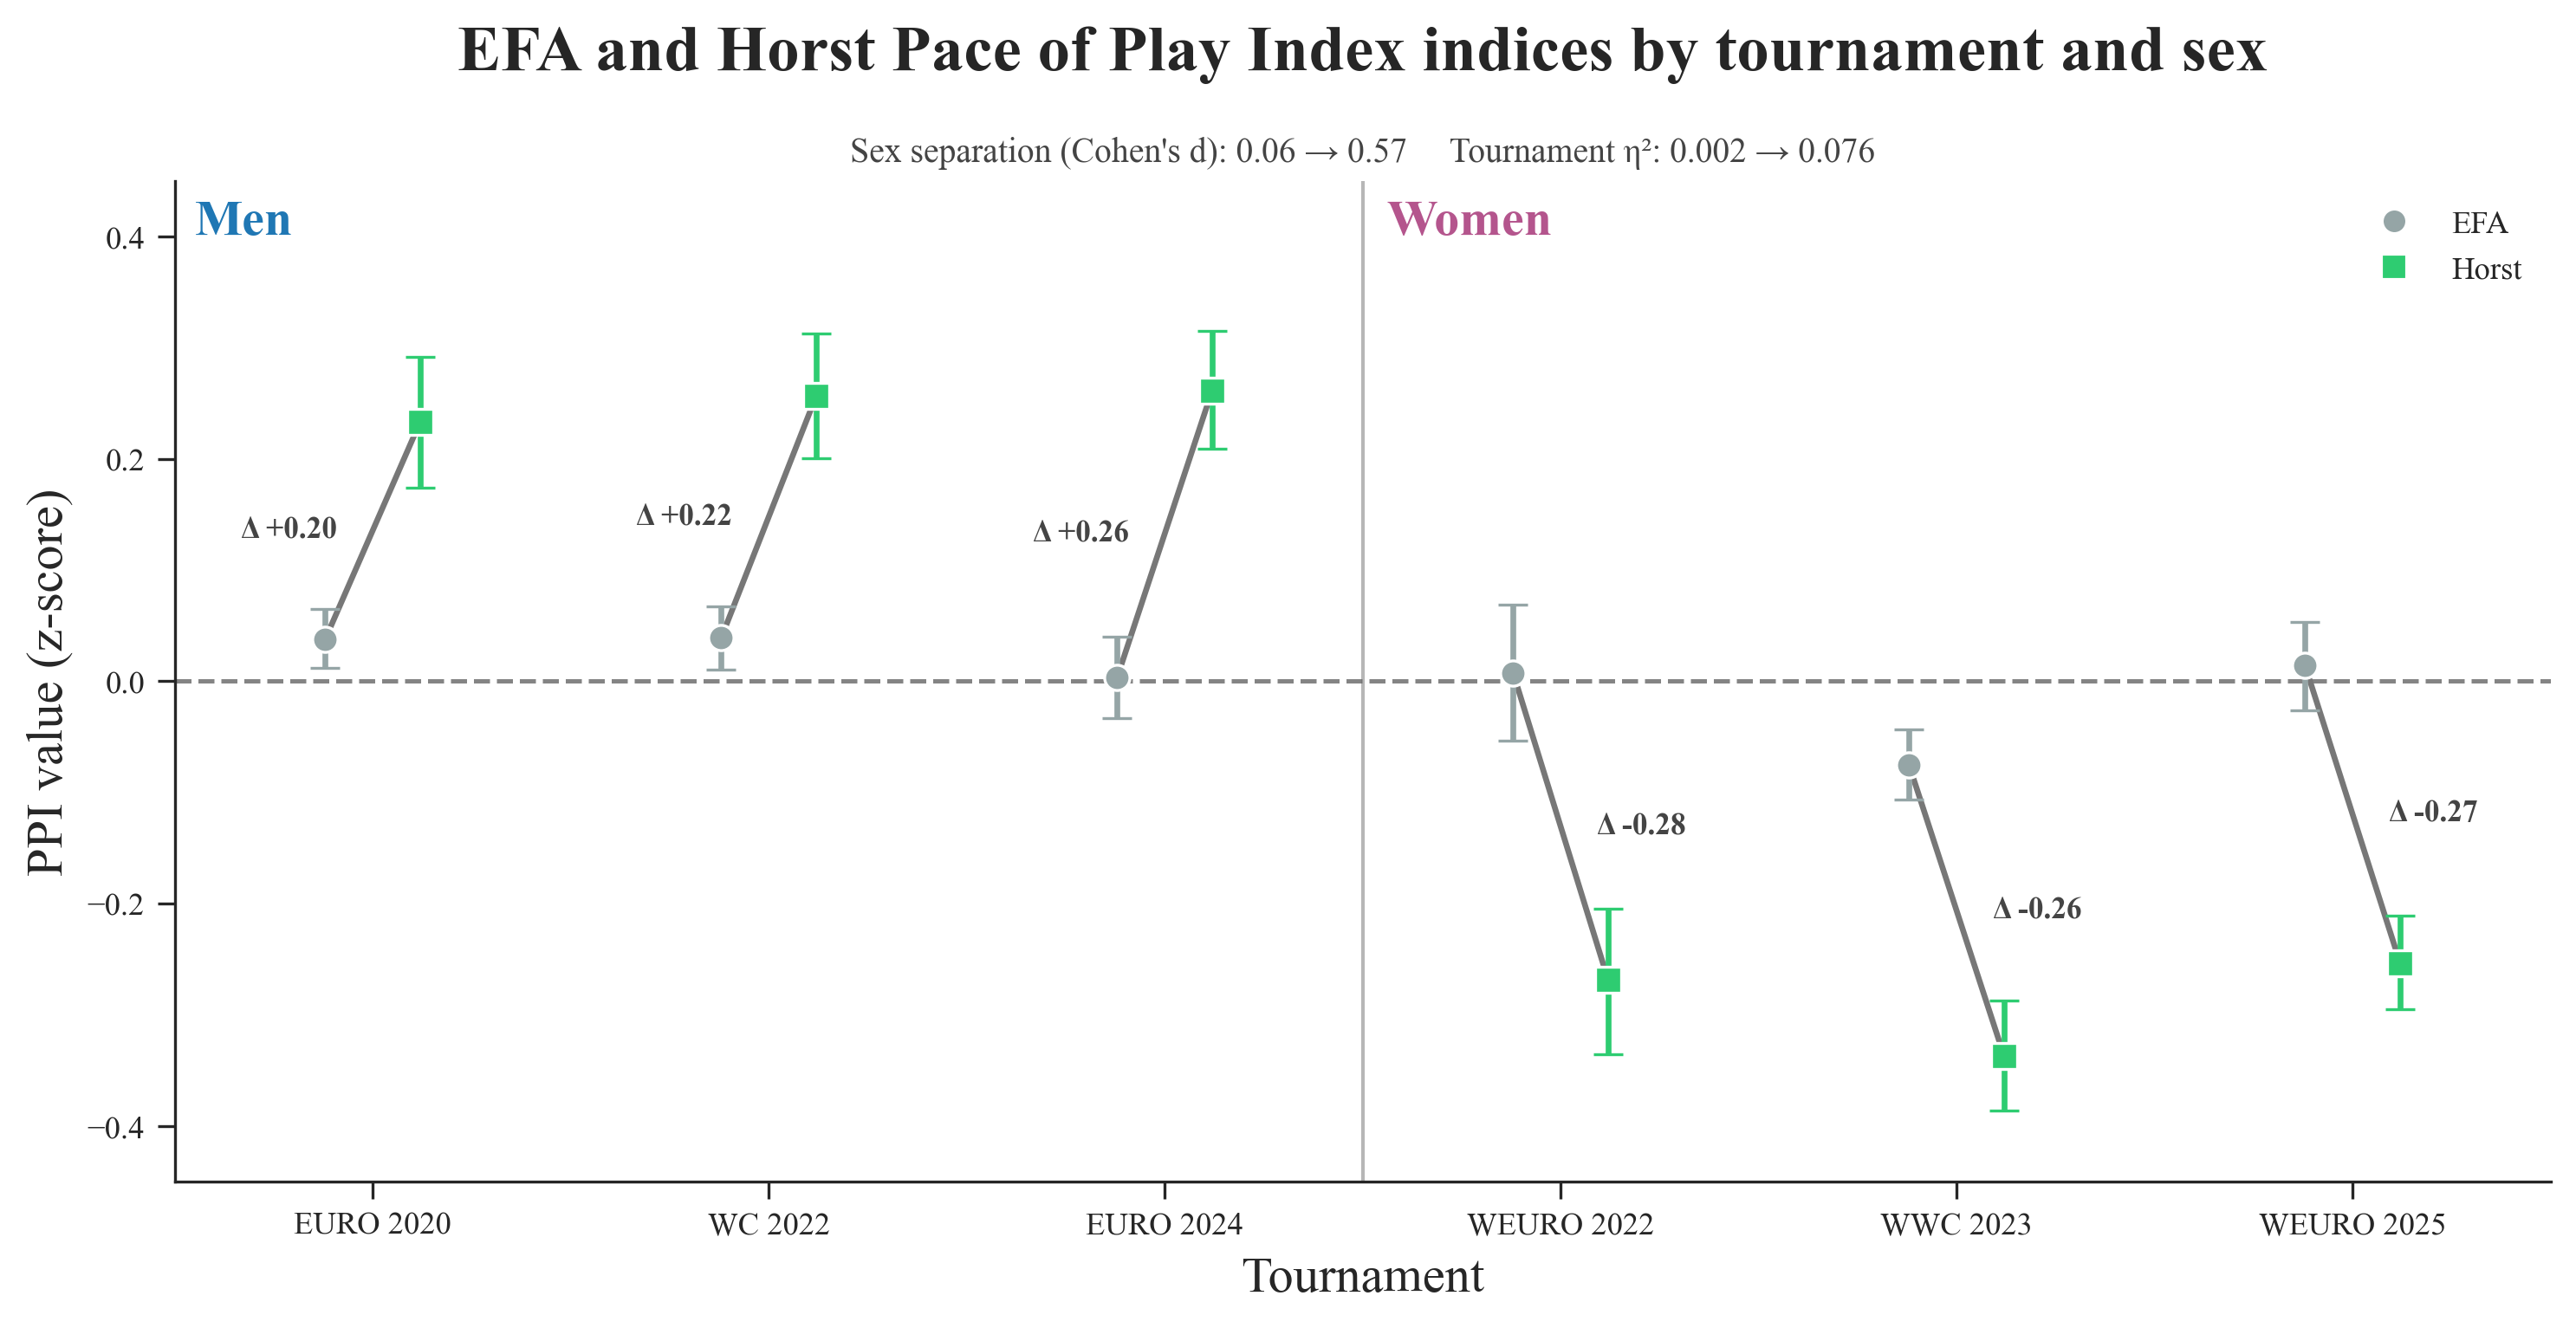

In [23]:
# paired EFA–Horst tournament means
from matplotlib.lines import Line2D

sns.set_theme(style="ticks", context="paper", font="Times New Roman")
plt.rcParams.update({
    "font.family": "Times New Roman",
    "font.serif": ["Times New Roman"],
    "mathtext.fontset": "stix",
})

# Men on the left, women on the right; 
TOURNAMENTS = ["EURO2020", "WC2022", "EURO2024",
               "WEURO2022", "WWC2023", "WEURO2025"]
TOURN_LABELS = {
    "EURO2020": "EURO 2020", "WC2022": "WC 2022", "EURO2024": "EURO 2024",
    "WEURO2022": "WEURO 2022", "WWC2023": "WWC 2023", "WEURO2025": "WEURO 2025",
}
X_POS = dict(zip(TOURNAMENTS, range(6)))
COLORS = {"EFA": "#95a5a6", "Horst": "#2ecc71"}
INDEX_COLS = {"EFA": "TI_efa", "Horst": "TI_horst"}
rng = np.random.default_rng(2025)

def _match_cluster_ci(sub, value_col, n_boot=4000):
    """Mean and 95% CI from a match-cluster bootstrap."""
    by_match = sub.groupby("game_id")[value_col].agg(["sum", "count"])
    sums = by_match["sum"].to_numpy()
    counts = by_match["count"].to_numpy()
    idx = rng.integers(0, len(by_match), size=(n_boot, len(by_match)))
    boot_means = sums[idx].sum(axis=1) / counts[idx].sum(axis=1)
    return sub[value_col].mean(), *np.quantile(boot_means, [0.025, 0.975])

summary_rows = []
for tourn in TOURNAMENTS:
    sub = tempo_df[tempo_df["tournament"] == tourn]
    for method, value_col in INDEX_COLS.items():
        mean, lo, hi = _match_cluster_ci(sub, value_col)
        summary_rows.append({"tournament": tourn, "method": method,
                             "mean": mean, "lo": lo, "hi": hi})
summary = pd.DataFrame(summary_rows)

def _gender_cohen_d(value_col):
    men = tempo_df.loc[tempo_df["gender"] == "Men", value_col]
    women = tempo_df.loc[tempo_df["gender"] == "Women", value_col]
    pooled_sd = np.sqrt(((len(men) - 1) * men.var(ddof=1) +
                         (len(women) - 1) * women.var(ddof=1)) /
                        (len(men) + len(women) - 2))
    return (men.mean() - women.mean()) / pooled_sd

def _tournament_eta2(value_col):
    grand_mean = tempo_df[value_col].mean()
    ss_between = sum(len(g) * (g[value_col].mean() - grand_mean) ** 2
                     for _, g in tempo_df.groupby("tournament"))
    ss_total = ((tempo_df[value_col] - grand_mean) ** 2).sum()
    return ss_between / ss_total

fig, ax = plt.subplots(figsize=(10, 5.2), dpi=300)


# ax.axvspan(-0.5, 2.5, color="#99d9d8", alpha=0.05, zorder=0)
# ax.axvspan(2.5, 5.5, color="#f1cacb", alpha=0.2, zorder=0)
ax.axvline(2.5, color="#B7B7B7", linestyle="-", linewidth=1.0, zorder=1)
ax.axhline(0, color="#666666", linestyle="--", linewidth=1.2,
           alpha=0.8, zorder=1)

for tourn in TOURNAMENTS:
    x = X_POS[tourn]
    pair = summary[summary["tournament"] == tourn].set_index("method")
    x_efa, x_horst = x - 0.12, x + 0.12
    y_efa, y_horst = pair.loc["EFA", "mean"], pair.loc["Horst", "mean"]
    ax.plot([x_efa, x_horst], [y_efa, y_horst],
            color="#777777", linewidth=1.6, zorder=2)

    for method, x_method, marker in [("EFA", x_efa, "o"),
                                      ("Horst", x_horst, "s")]:
        row = pair.loc[method]
        ax.errorbar(x_method, row["mean"],
                    yerr=[[row["mean"] - row["lo"]],
                          [row["hi"] - row["mean"]]],
                    fmt=marker, markersize=7, markerfacecolor=COLORS[method],
                    markeredgecolor="white", markeredgewidth=0.8,
                    color=COLORS[method], ecolor=COLORS[method],
                    elinewidth=1.6, capsize=4, capthick=1.4, zorder=4)

    delta = y_horst - y_efa
    is_men = x < 3
    ax.annotate(f"Δ {delta:+.2f}", (x, (y_efa + y_horst) / 2),
                xytext=(-10, 0) if is_men else (10, 0),
                textcoords="offset points",
                ha="right" if is_men else "left", va="center",
                fontsize=8.5, fontweight="bold", fontfamily="Times New Roman",
                color="#444444", zorder=5)

ax.text(-0.45, 0.98, "Men", transform=ax.get_xaxis_transform(),
        ha="left", va="top", fontsize=14, fontweight="bold",
        fontfamily="Times New Roman", color="#1f77b4")
ax.text(2.56, 0.98, "Women", transform=ax.get_xaxis_transform(),
        ha="left", va="top", fontsize=14, fontweight="bold",
        fontfamily="Times New Roman", color="#b4558d")

ax.set_xticks(range(6), [TOURN_LABELS[t] for t in TOURNAMENTS])
ax.set_xlim(-0.5, 5.5)
ax.set_ylim(-0.45, 0.45)
ax.set_yticks(np.arange(-0.4, 0.41, 0.2))
ax.set_xlabel("Tournament", fontfamily="Times New Roman", fontsize=14)
ax.set_ylabel("PPI value (z-score)", fontfamily="Times New Roman",
              fontsize=14)
ax.set_title("EFA and Horst Pace of Play Index indices by tournament and sex", fontsize=18,
             pad=31, fontweight="bold", fontfamily="Times New Roman")

metrics = (f"Sex separation (Cohen's d): "
           f"{_gender_cohen_d('TI_efa'):.2f} → {_gender_cohen_d('TI_horst'):.2f}     "
           f"Tournament η²: {_tournament_eta2('TI_efa'):.3f} → "
           f"{_tournament_eta2('TI_horst'):.3f}")
ax.text(0.5, 1.012, metrics, transform=ax.transAxes, ha="center", va="bottom",
        fontsize=9.5, fontfamily="Times New Roman", color="#444444")

legend = ax.legend(handles=[
    Line2D([0], [0], marker="o", color="none", markerfacecolor=COLORS["EFA"],
           markeredgecolor="white", label="EFA", markersize=7),
    Line2D([0], [0], marker="s", color="none", markerfacecolor=COLORS["Horst"],
           markeredgecolor="white", label="Horst", markersize=7),
], frameon=False, loc="upper right")
for label in list(ax.get_xticklabels()) + list(ax.get_yticklabels()) + list(legend.get_texts()):
    label.set_fontfamily("Times New Roman")

sns.despine(ax=ax)
for spine in ("left", "bottom"):
    ax.spines[spine].set_linewidth(0.8)
ax.tick_params(axis="both", width=0.8)
plt.tight_layout()

os.makedirs("figures", exist_ok=True)
fig.savefig("figures/Figure_c_EFA_Horst_by_tournament.png", dpi=300,
            bbox_inches="tight")
plt.show()

### Step 9 — Output & Methods paragraph

In [24]:
print("=" * 72)
print("FINAL SELECTED VARIABLES")
print("=" * 72)
print(FEATURES_FINAL)

print("\n" + "=" * 72)
print(f"FACTOR STRUCTURE  (promax, oblique, n_factors={N_FACTORS_FINAL})")
print("=" * 72)
disp_final = loadings_f.copy()
disp_final["h2"] = communal_f
disp_final["max_load"] = loadings_f.abs().max(axis=1)
print(disp_final.sort_values("max_load", ascending=False).round(3).to_string())

print("\n" + "=" * 72)
print("FACTOR INTER-CORRELATION MATRIX Φ (final solution)")
print("=" * 72)
_phi_final = pd.DataFrame(fa_final.phi_,
                          index=[f"F{i+1}" for i in range(N_FACTORS_FINAL)],
                          columns=[f"F{i+1}" for i in range(N_FACTORS_FINAL)])
print(_phi_final.round(3).to_string())
_off_final = fa_final.phi_[np.triu_indices_from(fa_final.phi_, k=1)]
print(f"|Φ off-diagonal|: mean={np.mean(np.abs(_off_final)):.3f}  "
      f"max={np.max(np.abs(_off_final)):.3f}")

print("\n" + "=" * 72)
print("VARIANCE EXPLAINED")
print("=" * 72)
for i, (ss, prop, cum) in enumerate(zip(*var_exp_f), 1):
    marker = " ← TEMPO" if f"F{i}" == tempo_col else ""
    print(f"  F{i}: SS={ss:.3f}  {prop*100:.1f}%  (cum {cum*100:.1f}%){marker}")

print("\n" + "=" * 72)
print("TEMPO INDEX DEFINITION")
print("=" * 72)
print(f"  Primary index : {tempo_col} factor scores (regression weights)")
print(f"  Anchor        : passes_per_minute  "
      f"(loading = {loadings_f.loc['passes_per_minute', tempo_col]:.3f})")
print(f"  Horst r       : {r_compare:.4f}")

FINAL SELECTED VARIABLES
['passes_per_minute', 'distance_per_second', 'distance_per_touch', 'time_to_pass', 'spatial_compression_x', 'spatial_compression_y', 'pass_completion_rate']

FACTOR STRUCTURE  (promax, oblique, n_factors=3)
                          F1     F2     F3     h2  max_load
passes_per_minute      0.958  0.171 -0.031  0.948     0.958
spatial_compression_y -0.023 -0.097  0.813  0.670     0.813
distance_per_touch    -0.229  0.758  0.261  0.695     0.758
time_to_pass           0.663 -0.142  0.092  0.469     0.663
distance_per_second    0.246  0.608 -0.023  0.431     0.608
spatial_compression_x  0.051  0.080  0.544  0.305     0.544
pass_completion_rate   0.066 -0.520  0.191  0.311     0.520

FACTOR INTER-CORRELATION MATRIX Φ (final solution)
       F1     F2     F3
F1  1.000 -0.117  0.080
F2 -0.117  1.000 -0.234
F3  0.080 -0.234  1.000
|Φ off-diagonal|: mean=0.144  max=0.234

VARIANCE EXPLAINED
  F1: SS=1.479  21.1%  (cum 21.1%) ← TEMPO
  F2: SS=1.279  18.3%  (cum 39.4%)
  

In [25]:
# ── Save both indices + all factor scores to combined h5 
tempo_df["TI_horst"] = TI_horst.values
factor_cols = [f"F{i+1}" for i in range(scores.shape[1])]
save_cols = ["game_id","possession","possession_team_id",
             "tournament","gender","TI_efa","TI_horst"] + factor_cols
tempo_df[save_cols].to_hdf(
    spadl_h5, key="efa_tempo_index", mode="a", complevel=5)
print(f"Saved efa_tempo_index → {spadl_h5}  ({len(tempo_df):,} rows)")
tempo_df[save_cols].head()

Saved efa_tempo_index → ../data/women-statsbomb3.h5  (39,995 rows)


,game_id,possession,possession_team_id,tournament,gender,TI_efa,TI_horst,F1,F2,F3
0,4020846,2,865,WEURO2025,Women,0.122384,1.143743,0.122384,0.414033,0.007227
1,4020846,4,865,WEURO2025,Women,0.375292,0.737501,0.375292,0.134878,-0.014533
2,4020846,5,865,WEURO2025,Women,0.009955,1.003642,0.009955,1.426399,1.172717
3,4020846,6,863,WEURO2025,Women,-0.612210,-0.312312,-0.612210,-0.516236,0.273397
4,4020846,7,865,WEURO2025,Women,-0.634556,-0.411191,-0.634556,-0.550798,0.020664


## Criterion validity — outcome-based validation

Construct validity (gender / tournament differences) shows the index *varies*
where theory predicts; **criterion validity** asks whether it relates to a
behavioural outcome of the possession. The natural criterion for a possession
pace index is the possession's own attacking outcome:

1. **Did the possession end in a shot?** (all possessions) — known-groups +
   mixed-effects logistic regression `shot ~ PPI + (1 | match)`.
2. **How good was the shot (xG)?** (shot possessions only) — mixed-effects
   linear regression `xG ~ PPI + (1 | match)`.

A random intercept per match (`game_id`) absorbs the clustering of possessions
within games (and thus within team / tournament), which a pooled regression
would ignore — inflating significance. `PPI ≡ TI_horst` (the z-standardised
Horst composite); higher = faster, more coordinated pace.


In [26]:
# ── Possession outcomes (shot + xG) from raw Shot events ─────────────────────
# Reads Shot events from both source h5 files and aggregates to possession level
# (n_shots, max statsbomb_xg). Keyed on the natural (game_id, possession,
# possession_team_id) tuple so it joins directly onto the tempo index.

def _extract_shot_outcomes(h5, game_ids):
    rows = []
    for gid in tqdm.tqdm(game_ids, desc=f"Shots {os.path.basename(h5)}"):
        try:
            ev = pd.read_hdf(h5, f"events/game_{gid}")
        except Exception:
            continue
        sh = ev[ev["type_name"] == "Shot"]
        # Keep only shots taken by the possession team itself — a small share
        # (~1.5%) of Shot events are logged under the opponent's possession
        # (rebounds / deflections) and would be mis-attributed otherwise.
        sh = sh[sh["team_id"] == sh["possession_team_id"]]
        if len(sh) == 0:
            continue
        sh = sh.assign(xg=sh["extra"].apply(
            lambda ex: ex.get("shot", {}).get("statsbomb_xg", np.nan)
            if isinstance(ex, dict) else np.nan))
        rows.append(
            sh.groupby(["game_id", "possession", "possession_team_id"])
              .agg(n_shots=("xg", "size"), xg_max=("xg", "max"), xg_sum=("xg", "sum"))
              .reset_index())
    return pd.concat(rows, ignore_index=True)

shot_outcomes = pd.concat([
    _extract_shot_outcomes(spadl_h5, games["game_id"].tolist()),
    _extract_shot_outcomes(men_h5,   men_games["game_id"].tolist()),
], ignore_index=True)

KEY = ["game_id", "possession", "possession_team_id"]
val_df = tempo_df.merge(shot_outcomes, on=KEY, how="left")
val_df["shot"] = val_df["n_shots"].notna().astype(int)
val_df["PPI"]  = val_df["TI_horst"]                 # primary pace index

print(f"Possessions with PPI : {len(val_df):,}")
print(f"  ending in a shot   : {val_df['shot'].sum():,} "
      f"({100 * val_df['shot'].mean():.1f}%)")

val_df.to_hdf(spadl_h5, key="criterion_validity", mode="a", complevel=5)
print(f"Saved criterion_validity → {spadl_h5}")


Shots men-statsbomb.h5: 100%|██████████| 166/166 [00:04<00:00, 34.17it/s]


Possessions with PPI : 39,995
  ending in a shot   : 5,704 (14.3%)
Saved criterion_validity → ../data/women-statsbomb3.h5


In [27]:
# ── Table: PPI in shot vs non-shot possessions (known-groups validity) ───────
from scipy import stats

g0 = val_df.loc[val_df.shot == 0, "PPI"]
g1 = val_df.loc[val_df.shot == 1, "PPI"]
n0, n1 = len(g0), len(g1)
sp = np.sqrt(((n0 - 1) * g0.var(ddof=1) + (n1 - 1) * g1.var(ddof=1)) / (n0 + n1 - 2))
cohen_d = (g1.mean() - g0.mean()) / sp
U, p_mw = stats.mannwhitneyu(g1, g0, alternative="two-sided")

desc = pd.DataFrame({
    "Outcome":  ["No shot", "Shot"],
    "n":        [n0, n1],
    "PPI mean": [g0.mean(), g1.mean()],
    "PPI SD":   [g0.std(),  g1.std()],
}).round(3)
print(desc.to_string(index=False))
print(f"\nCohen's d = {cohen_d:+.3f}   Mann–Whitney U p = {p_mw:.2e}")

Outcome     n  PPI mean  PPI SD
No shot 34291     0.056   0.998
   Shot  5704    -0.335   0.948

Cohen's d = -0.395   Mann–Whitney U p = 4.86e-176


In [28]:
# ── Model 1: mixed-effects logistic  shot ~ PPI + (1 | match) ────────────────
# Random intercept per match (game_id) absorbs between-match clustering of
# possessions. Variational Bayes fit; OR and 95% CI from the posterior mean/SD.
from statsmodels.genmod.bayes_mixed_glm import BinomialBayesMixedGLM

m1 = BinomialBayesMixedGLM.from_formula(
    "shot ~ PPI", {"match": "0 + C(game_id)"}, val_df).fit_vb()
j     = list(m1.model.exog_names).index("PPI")
b, se = m1.fe_mean[j], m1.fe_sd[j]
print("Model 1   shot ~ PPI + (1 | match)")
print(f"  OR = {np.exp(b):.3f}   95% CI [{np.exp(b - 1.96 * se):.3f}, "
      f"{np.exp(b + 1.96 * se):.3f}]   (β = {b:+.3f}, SE = {se:.3f})")

Model 1   shot ~ PPI + (1 | match)
  OR = 0.668   95% CI [0.651, 0.686]   (β = -0.403, SE = 0.013)


In [29]:
# ── Model 2: mixed-effects linear  xG ~ PPI + (1 | match) | shot possessions ─
# Outcome = possession total xG (sum of statsbomb_xg over the possession's shots).
import statsmodels.formula.api as smf

shots = val_df[val_df.shot == 1].dropna(subset=["xg_sum", "PPI"]).copy()
m2 = smf.mixedlm("xg_sum ~ PPI", shots, groups=shots["game_id"]).fit()
b2, (lo, hi) = m2.params["PPI"], m2.conf_int().loc["PPI"]
print(f"Model 2   xG(sum) ~ PPI + (1 | match)   (n = {len(shots):,} shot possessions)")
print(f"  β = {b2:+.4f}   95% CI [{lo:+.4f}, {hi:+.4f}]   p = {m2.pvalues['PPI']:.3g}")

Model 2   xG(sum) ~ PPI + (1 | match)   (n = 5,704 shot possessions)
  β = -0.0022   95% CI [-0.0060, +0.0016]   p = 0.264


/opt/miniconda3/envs/pace/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
